# Optimasi Portofolio MVSK (NSGA-III vs GA)

In [1]:
# @core
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import wilcoxon, rankdata
from joblib import Parallel, delayed

# Warna tetap: aset sama dengan nbeats_dulu.ipynb, NSGA-III biru dan GA hijau (gradasi per model), aman buta warna
WARNA = {
    "GLD": "#009E73", "IBIT": "#D55E00", "SPY": "#0072B2",
    "NSGA-III": "#3683c8", "GA": "#30954f",
    "NSGA-III · N-BEATS": "#3683c8", "NSGA-III · LSTM": "#70b8fe", "NSGA-III · N-BEATS + LSTM": "#01528d",
    "GA · N-BEATS": "#30954f", "GA · LSTM": "#6acb81", "GA · N-BEATS + LSTM": "#026129"
}
GAYA_BENCHMARK = {
    "Equal Weight (rebalance)": dict(color="#262626", linestyle="--", linewidth=1.3),
    "Equal Weight (buy & hold)": dict(color="#262626", linestyle=":", linewidth=1.7)
}
GARIS = {"nbeats": "-", "lstm": "--", "kombinasi": "-."}
NAMA = {"nbeats": "N-BEATS", "lstm": "LSTM", "kombinasi": "N-BEATS + LSTM",
        "dengan_biaya": "biaya 0,3%", "tanpa_biaya": "tanpa biaya"}

plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 10,
    "lines.linewidth": 1.8, "axes.spines.top": False, "axes.spines.right": False
})

FIG_DIR = Path("gambar_portofolio")
FIG_DIR.mkdir(exist_ok=True)


def simpan_tampil(nama, fig):
    fig.savefig(FIG_DIR / f"{nama}.png", dpi=300, bbox_inches="tight")
    plt.show()


def sumbu_bulanan(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.MonthLocator()))

In [2]:
# @core
# Konfigurasi

ASSETS = ["IBIT", "GLD", "SPY"]          # urutan i = 1,2,3 sesuai proposal
N_ASSETS = len(ASSETS)

TC_RATE = 0.003                          # biaya transaksi 0,3% (batasan 10)

# tanpa_biaya: biaya 0 di f1 dan di pembukuan nilai portofolio
TC_RATES = {"dengan_biaya": TC_RATE, "tanpa_biaya": 0.0}
INITIAL_CAPITAL = 1000.0

WINDOWS = [63, 126, 252]                 # rolling window hari perdagangan: 3, 6, 12 bulan (21 hari/bulan)

FORECAST_MODELS = ["nbeats", "lstm"]

# (frekuensi, mode, kolom expected return); arti mode di NBEATS_NOTES.md
SCENARIOS = [
    ("mingguan", "t_akhir", "Forecast Return"),
    ("harian", "t+1", None)
]

FREQUENCIES = ["mingguan", "harian"]

# Horizon return untuk estimasi ko-momen, mengikuti frekuensi rebalancing
RETURN_STEP = {"mingguan": 5, "harian": 1}

# Metrik kinerja dihitung dari return harian nilai portofolio (persamaan 2.78-2.80) untuk semua frekuensi
TRADING_DAYS = 252

COMBINATIONS = [
    (model, freq, mode, biaya)
    for model in FORECAST_MODELS
    for freq, mode, _ in SCENARIOS
    for biaya in TC_RATES
]

# Kombinasi N-BEATS + LSTM: model per aset per periode dipilih dari error forecast periode sebelumnya
COMBINED = "kombinasi"

COMBINATIONS += [
    (COMBINED, freq, mode, biaya)
    for freq, mode, _ in SCENARIOS
    for biaya in TC_RATES
]

MODELS = FORECAST_MODELS + [COMBINED]

# Kriteria pemilihan λ GA di validasi; harus metrik yang makin besar makin baik
LAMBDA_CRITERION = "Total Return (%)"

N_SEEDS = 30                             # replikasi independen

POP_PARTITIONS = 8                       # p pada Das-Dennis -> H = C(4+8-1,8) = 165
N_GEN = 50                               # cek di sel konvergensi hypervolume
N_GEN_TUNING = N_GEN

N_JOBS = os.cpu_count()                  # paralel antar λ dan seed, hasil tetap identik

EPS = 1e-12

print(f"{len(COMBINATIONS)} skenario x {len(WINDOWS)} window")
for model, freq, mode, biaya in COMBINATIONS:
    print(f"  {model:6s} | {freq:8s} | {mode:9s} | {biaya}")

12 skenario x 3 window
  nbeats | mingguan | t_akhir   | dengan_biaya
  nbeats | mingguan | t_akhir   | tanpa_biaya
  nbeats | harian   | t+1       | dengan_biaya
  nbeats | harian   | t+1       | tanpa_biaya
  lstm   | mingguan | t_akhir   | dengan_biaya
  lstm   | mingguan | t_akhir   | tanpa_biaya
  lstm   | harian   | t+1       | dengan_biaya
  lstm   | harian   | t+1       | tanpa_biaya
  kombinasi | mingguan | t_akhir   | dengan_biaya
  kombinasi | mingguan | t_akhir   | tanpa_biaya
  kombinasi | harian   | t+1       | dengan_biaya
  kombinasi | harian   | t+1       | tanpa_biaya


## 1. Data dan Hasil Forecast

In [3]:
# @core
prices = (
    pd.read_csv("data_IBIT_GLD_SPY.csv", index_col="Date", parse_dates=["Date"])
    .sort_index()
    .astype(float)
)[ASSETS]

print(prices.shape, prices.index.min().date(), "s/d", prices.index.max().date())
prices.tail()

(660, 3) 2024-01-11 s/d 2026-08-28


,IBIT,GLD,SPY
Date,,,
2026-08-24,44.639999,426.690002,763.469971
2026-08-25,44.720001,428.070007,765.909973
2026-08-26,44.459999,421.320007,766.080017
2026-08-27,45.290001,422.600006,771.099976
2026-08-28,43.900002,408.890015,769.349976


In [4]:
def load_forecast(path, tanggal=("Rebalance Date", "Target Date")):
    """Membaca CSV forecast dan menyaring model yang dibandingkan."""

    frame = pd.read_csv(path, parse_dates=list(tanggal))

    frame = frame[frame["Model"].isin(FORECAST_MODELS)].copy()

    kurang = set(FORECAST_MODELS) - set(frame["Model"])
    assert not kurang, f"model kurang pada {path}: {kurang}"

    return frame


weekly_test = load_forecast("forecast_weekly_test.csv")
weekly_val = load_forecast("forecast_weekly_val.csv")

daily_test = load_forecast("forecast_daily_test.csv", tanggal=("Date",))
daily_val = load_forecast("forecast_daily_val.csv", tanggal=("Date",))

assert "Forecast 1-step" in daily_test.columns, (
    "Kolom 'Forecast 1-step' tidak ada. Jalankan ulang nbeats_dulu.ipynb versi terbaru."
)

print("mingguan:", weekly_test.shape, weekly_val.shape)
print("harian  :", daily_test.shape, daily_val.shape)
daily_test.head()

mingguan: (120, 19) (126, 19)
harian  : (582, 8) (594, 8)


,Date,Asset,Model,Split,Actual,Forecast,Forecast 1-step,Previous Actual
0,2026-04-13,GLD,nbeats,test,435.359985,437.264108,439.599883,437.130005
1,2026-04-14,GLD,nbeats,test,445.089996,437.006111,438.036469,435.359985
2,2026-04-15,GLD,nbeats,test,440.459991,436.720692,445.776207,445.089996
3,2026-04-16,GLD,nbeats,test,440.079987,436.223481,443.394901,440.459991
4,2026-04-17,GLD,nbeats,test,445.929993,435.802297,442.370486,440.079987


### Jadwal Rebalancing Mingguan dan Harian

In [5]:
# @core
def build_weekly(frame):
    """Rebalancing di hari perdagangan terakhir tiap minggu kalender."""

    r_hat = {}
    schedule = None

    for model in FORECAST_MODELS:

        sub = frame[frame["Model"] == model]

        target = sub.pivot(index="Rebalance Date", columns="Asset",
                           values="Target Date")[ASSETS]

        assert target.nunique(axis=1).eq(1).all(), "Target Date berbeda antar aset"

        jadwal = pd.DataFrame({
            "Rebalance Date": target.index,
            "Target Date": target.iloc[:, 0].values
        }).reset_index(drop=True)

        if schedule is None:
            schedule = jadwal
        else:
            assert schedule.equals(jadwal), "jadwal berbeda antar model"

        for _, mode, column in SCENARIOS:

            if column is None:
                continue

            pivot = sub.pivot(index="Rebalance Date", columns="Asset",
                              values=column)[ASSETS]

            assert not pivot.isna().any().any(), f"expected return hilang: {column}"

            r_hat[(model, mode)] = pivot.values

    return schedule, r_hat


def build_daily(frame):
    """Rebalancing setiap hari perdagangan, memakai ramalan 1 langkah."""

    dates = pd.DatetimeIndex(sorted(frame["Date"].unique()))

    posisi = prices.index.get_indexer(dates)

    assert (posisi > 0).all(), "ada tanggal tanpa hari perdagangan sebelumnya"

    schedule = pd.DataFrame({
        "Rebalance Date": prices.index[posisi - 1],
        "Target Date": dates
    }).reset_index(drop=True)

    r_hat = {}

    for model in FORECAST_MODELS:

        sub = frame[frame["Model"] == model].copy()

        sub["R"] = sub["Forecast 1-step"] / sub["Previous Actual"] - 1.0

        pivot = sub.pivot(index="Date", columns="Asset", values="R")[ASSETS]

        assert not pivot.isna().any().any(), "expected return harian hilang"
        assert (pivot.index == dates).all()

        r_hat[(model, "t+1")] = pivot.values

    return schedule, r_hat

In [6]:
# @core
def realized_returns(prices, schedule):
    """Return realisasi dari Rebalance Date ke Target Date."""

    p_start = prices.loc[schedule["Rebalance Date"]].values
    p_end = prices.loc[schedule["Target Date"]].values

    return p_end / p_start - 1.0


SKEMA = {}

for freq, builder, frame_test, frame_val in [
    ("mingguan", build_weekly, weekly_test, weekly_val),
    ("harian", build_daily, daily_test, daily_val),
]:
    schedule_test, r_hat_test = builder(frame_test)
    schedule_val, r_hat_val = builder(frame_val)

    SKEMA[freq] = {
        "schedule_test": schedule_test,
        "schedule_val": schedule_val,
        "r_hat_test": r_hat_test,
        "r_hat_val": r_hat_val,
        "realized_test": realized_returns(prices, schedule_test),
        "realized_val": realized_returns(prices, schedule_val),
    }

    print(f"{freq:8s}: {len(schedule_test):3d} periode test, "
          f"{len(schedule_val):3d} periode validasi")

mingguan:  20 periode test,  21 periode validasi
harian  :  97 periode test,  99 periode validasi


In [7]:
# @core
# Model kombinasi: tiap aset per periode memakai model dengan error forecast periode sebelumnya terkecil (tanpa look-ahead)
def pilih_model(galat, tanggal):
    """galat: error forecast, indeks periode validasi+test berurutan, kolom (Model, Asset). Error sama atau belum ada periode sebelumnya -> nbeats."""

    sebelumnya = galat.shift(1)

    pilihan = pd.DataFrame("nbeats", index=galat.index, columns=ASSETS)
    pilihan[sebelumnya["lstm"][ASSETS] < sebelumnya["nbeats"][ASSETS]] = "lstm"

    return pilihan.loc[tanggal]


# Mingguan: RMSE return forecast minggu sebelumnya; minggu itu selesai tepat di tanggal rebalancing
mingguan_all = pd.concat([weekly_val, weekly_test])
galat_mingguan = mingguan_all.pivot(index="Rebalance Date", columns=["Model", "Asset"],
                                    values="RMSE Return").sort_index()

target = mingguan_all.groupby("Rebalance Date")["Target Date"].first().sort_index()
assert (target.values[:-1] <= target.index.values[1:]).all(), "minggu sebelumnya belum selesai saat rebalancing"

# Harian: error absolut forecast 1 langkah hari sebelumnya (RMSE satu titik)
harian_all = pd.concat([daily_val, daily_test])
harian_all["Galat"] = (harian_all["Forecast 1-step"] - harian_all["Actual"]).abs()
galat_harian = harian_all.pivot(index="Date", columns=["Model", "Asset"], values="Galat").sort_index()

for freq, galat, kolom_tanggal in [
    ("mingguan", galat_mingguan, "Rebalance Date"),
    ("harian", galat_harian, "Target Date"),
]:
    data = SKEMA[freq]

    for split in ["test", "val"]:

        pilihan = pilih_model(galat, data[f"schedule_{split}"][kolom_tanggal])
        data[f"pilihan_{split}"] = pilihan

        r_hat = data[f"r_hat_{split}"]
        for model, mode in [k for k in r_hat if k[0] == "nbeats"]:
            r_hat[(COMBINED, mode)] = np.where(
                pilihan.values == "lstm", r_hat[("lstm", mode)], r_hat[("nbeats", mode)])

    print(f"{freq:8s}: proporsi periode test memakai LSTM -> "
          + ", ".join(f"{a} {(data['pilihan_test'][a] == 'lstm').mean():.0%}" for a in ASSETS))

mingguan: proporsi periode test memakai LSTM -> IBIT 55%, GLD 35%, SPY 25%
harian  : proporsi periode test memakai LSTM -> IBIT 49%, GLD 41%, SPY 32%


In [8]:
# Pemeriksaan jadwal

for freq in FREQUENCIES:
    schedule = SKEMA[freq]["schedule_test"]
    hari = schedule["Rebalance Date"].dt.day_name().value_counts()
    print(f"\n{freq} - {len(schedule)} tanggal rebalancing:")
    print(hari.to_string())

    # Target Date periode t harus jadi Rebalance Date periode t+1
    sambung = (schedule["Target Date"].values[:-1]
               == schedule["Rebalance Date"].values[1:]).all()
    print(f"  Target Date = Rebalance Date periode berikutnya: {sambung}")

mingguan = SKEMA["mingguan"]["schedule_test"]
bukan_jumat = mingguan[mingguan["Rebalance Date"].dt.weekday != 4]
print(f"\nRebalancing mingguan yang bukan Jumat: {len(bukan_jumat)}")
print(bukan_jumat.to_string(index=False))


mingguan - 20 tanggal rebalancing:
Rebalance Date
Friday      18
Thursday     2
  Target Date = Rebalance Date periode berikutnya: True

harian - 97 tanggal rebalancing:
Rebalance Date
Tuesday      20
Thursday     20
Wednesday    20
Monday       19
Friday       18
  Target Date = Rebalance Date periode berikutnya: True

Rebalancing mingguan yang bukan Jumat: 2
Rebalance Date Target Date
    2026-06-18  2026-06-26
    2026-07-02  2026-07-10


## 2. Ko-momen (rolling window, horizon return mengikuti frekuensi rebalancing)

In [9]:
# @core
def window_weekly_returns(prices, end_date, window_days, step=5):
    """`window_days` return overlapping `step` hari terakhir (persamaan 2.15), dari `window_days + step` harga."""

    history = prices.loc[:end_date].iloc[-(window_days + step):].values

    if len(history) < window_days + step:
        raise ValueError("Harga sebelum tanggal ini kurang dari window + step")

    return history[step:] / history[:-step] - 1.0


def comoments(returns):
    """Mengembalikan (mu, Sigma (N,N), M3 (N,N,N), M4 (N,N,N,N))."""

    returns = np.asarray(returns, dtype=float)

    h = len(returns)

    mu = returns.mean(axis=0)
    d = returns - mu

    sigma = d.T @ d / h
    m3 = np.einsum("ti,tj,tk->ijk", d, d, d) / h
    m4 = np.einsum("ti,tj,tk,tl->ijkl", d, d, d, d) / h

    return mu, sigma, m3, m4


def portfolio_moments(weights, sigma, m3, m4):
    """Volatilitas, skewness, kurtosis portofolio; weights (N,) atau (n_solusi, N)."""

    w = np.atleast_2d(np.asarray(weights, dtype=float))

    variance = np.maximum(np.einsum("si,ij,sj->s", w, sigma, w), EPS)

    sd = np.sqrt(variance)

    third = np.einsum("si,sj,sk,ijk->s", w, w, w, m3)
    fourth = np.einsum("si,sj,sk,sl,ijkl->s", w, w, w, w, m4)

    return sd, third / sd ** 3, fourth / sd ** 4

In [10]:
# @core
def precompute_moments(prices, schedule, windows, step):
    """(Sigma, M3, M4) per tanggal rebalancing untuk tiap panjang jendela."""

    return {
        window: [comoments(window_weekly_returns(prices, date, window, step))[1:]
                 for date in schedule["Rebalance Date"]]
        for window in windows
    }


for freq in FREQUENCIES:

    step = RETURN_STEP[freq]

    for split in ["test", "val"]:
        SKEMA[freq][f"moments_{split}"] = precompute_moments(
            prices, SKEMA[freq][f"schedule_{split}"], WINDOWS, step)

    print(f"{freq:8s} step={step} | n return per jendela: "
          + ", ".join(f"h={w} -> {len(window_weekly_returns(prices, prices.index[-1], w, step))}" for w in WINDOWS))

mingguan step=5 | n return per jendela: h=63 -> 63, h=126 -> 126, h=252 -> 252
harian   step=1 | n return per jendela: h=63 -> 63, h=126 -> 126, h=252 -> 252


In [11]:
# Ko-momen historis antar aset

summary_rows = []

for freq in FREQUENCIES:
    for window in WINDOWS:

        mu, sigma, m3, m4 = comoments(
            window_weekly_returns(prices, prices.index[-1], window, RETURN_STEP[freq])
        )

        for i, asset in enumerate(ASSETS):
            sd = np.sqrt(sigma[i, i])
            summary_rows.append({
                "Frekuensi": freq,
                "Window": window,
                "Asset": asset,
                "Mean (%)": mu[i] * 100,
                "Std (%)": sd * 100,
                "Skewness": m3[i, i, i] / sd ** 3,
                "Kurtosis": m4[i, i, i, i] / sd ** 4
            })

comoment_summary = pd.DataFrame(summary_rows)
print(comoment_summary.to_string(index=False))

Frekuensi  Window Asset  Mean (%)  Std (%)  Skewness  Kurtosis
 mingguan      63  IBIT  0.713004 7.788799  0.644416  4.452584
 mingguan      63   GLD  0.220123 3.563196 -0.055190  2.945162
 mingguan      63   SPY  0.200575 1.826381  0.282659  3.182000
 mingguan     126  IBIT  0.881357 6.316354  0.551114  5.295262
 mingguan     126   GLD -0.425531 3.802397 -0.413926  3.692713
 mingguan     126   SPY  0.475850 1.975920  0.271088  2.589837
 mingguan     252  IBIT -0.506781 6.353925  0.050858  4.849294
 mingguan     252   GLD  0.684292 3.888786 -0.454292  3.857924
 mingguan     252   SPY  0.387417 1.711134  0.219557  3.109204
   harian      63  IBIT  0.118167 2.608793  0.272712  3.006551
   harian      63   GLD -0.017393 1.685937 -0.088298  3.097160
   harian      63   SPY  0.034533 0.856015 -0.168779  3.576665
   harian     126  IBIT  0.162009 2.468302  0.324469  3.202959
   harian     126   GLD -0.118695 1.708994 -0.120869  3.135139
   harian     126   SPY  0.099128 0.878878  0.024456  3

## 3. Fungsi Objektif (keempatnya dibuat minimisasi)

In [12]:
# @core
def drift_weights(w_target, asset_returns):
    """Bobot setelah pergeseran harga, persamaan (2.38)."""

    value = np.asarray(w_target, dtype=float) * (1.0 + np.asarray(asset_returns, dtype=float))

    total = value.sum()

    if total <= 0:
        raise ValueError("Nilai portofolio tidak positif")

    return value / total


def transaction_cost(weights, w_minus, rate=TC_RATE):
    """Biaya transaksi linier berbentuk V, persamaan (2.39)."""

    w = np.atleast_2d(np.asarray(weights, dtype=float))

    return rate * np.abs(w - np.asarray(w_minus, dtype=float)).sum(axis=1)


def evaluate_objectives(weights, r_hat, w_minus, sigma, m3, m4, rate=TC_RATE):
    """Keempat objektif arah minimisasi; (n_solusi, N) -> (n_solusi, 4)."""

    w = np.atleast_2d(np.asarray(weights, dtype=float))

    expected_return = w @ np.asarray(r_hat, dtype=float)

    cost = transaction_cost(w, w_minus, rate)

    sd, skewness, kurtosis = portfolio_moments(w, sigma, m3, m4)

    return np.column_stack([
        -(expected_return - cost),   # f1
        sd,                          # f2
        -skewness,                   # f3
        kurtosis                     # f4
    ])


OBJECTIVE_NAMES = ["-(E[R] - TC)", "Volatilitas", "-Skewness", "Kurtosis"]

In [13]:
# @core
def normalize_weights(X):
    """Proyeksi ke simpleks; baris nol jadi equal weight."""

    X = np.clip(np.atleast_2d(np.asarray(X, dtype=float)), 0.0, None)

    total = X.sum(axis=1, keepdims=True)

    degenerate = total[:, 0] <= EPS

    X[degenerate] = 1.0 / X.shape[1]
    total[degenerate] = 1.0

    return X / total

## 4. Entropy Weight-TOPSIS (pilih satu solusi dari Pareto front)

In [14]:
# @core
def entropy_topsis(F):
    """F (S, M) arah minimisasi -> (indeks terpilih, bobot entropi, closeness)."""

    F = np.atleast_2d(np.asarray(F, dtype=float))

    n_solution, n_objective = F.shape

    if n_solution == 1:
        return 0, np.full(n_objective, 1.0 / n_objective), np.ones(1)

    # Langkah 1: translasi agar seluruh elemen non-negatif
    X = F - F.min(axis=0) + EPS

    # Langkah 2: proporsi tiap solusi pada kriteria j
    column_sum = X.sum(axis=0)
    column_sum[column_sum <= 0] = 1.0

    P = X / column_sum

    # Langkah 3: entropi dan bobot objektif
    with np.errstate(divide="ignore", invalid="ignore"):
        p_log_p = np.where(P > 0, P * np.log(P), 0.0)

    entropy = -p_log_p.sum(axis=0) / np.log(n_solution)

    divergence = 1.0 - entropy

    if divergence.sum() <= EPS:
        lam = np.full(n_objective, 1.0 / n_objective)
    else:
        lam = divergence / divergence.sum()

    # Langkah 4-5: normalisasi vektor lalu pembobotan
    norm = np.sqrt((X ** 2).sum(axis=0))
    norm[norm <= 0] = 1.0

    V = lam * (X / norm)

    # Langkah 6: solusi ideal positif (min) dan negatif (max)
    ideal_best = V.min(axis=0)
    ideal_worst = V.max(axis=0)

    distance_best = np.linalg.norm(V - ideal_best, axis=1)
    distance_worst = np.linalg.norm(V - ideal_worst, axis=1)

    denominator = distance_best + distance_worst
    denominator[denominator <= 0] = 1.0

    # Langkah 7: closeness coefficient
    closeness = distance_worst / denominator

    return int(np.argmax(closeness)), lam, closeness

## 5. Algoritma Optimasi (pymoo)

In [15]:
from pymoo.core.problem import Problem
from pymoo.core.repair import Repair
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

REF_DIRS = get_reference_directions("das-dennis", 4, n_partitions=POP_PARTITIONS)

POP_SIZE = int(np.ceil(len(REF_DIRS) / 4) * 4)

# Grid λ GA = titik referensi NSGA-III
LAMBDA_GRID = REF_DIRS

print(f"Titik referensi H = {len(REF_DIRS)} | ukuran populasi = {POP_SIZE}")
print(f"Grid λ GA            = {len(LAMBDA_GRID)}")

Titik referensi H = 165 | ukuran populasi = 168
Grid λ GA            = 165


In [16]:
class SimplexRepair(Repair):
    """Memaksa setiap individu memenuhi w >= 0 dan sum(w) = 1."""

    def _do(self, problem, X, **kwargs):
        return normalize_weights(X)


class MVSKProblem(Problem):
    """Persamaan (2.41); lam=None -> empat objektif, lam=vektor -> skalarisasi (2.61)."""

    def __init__(self, r_hat, w_minus, sigma, m3, m4,
                 lam=None, scales=None, rate=TC_RATE):

        super().__init__(
            n_var=N_ASSETS,
            n_obj=1 if lam is not None else 4,
            n_ieq_constr=0,
            xl=0.0,
            xu=1.0
        )

        self.r_hat = np.asarray(r_hat, dtype=float)
        self.w_minus = np.asarray(w_minus, dtype=float)
        self.sigma = sigma
        self.m3 = m3
        self.m4 = m4
        self.lam = None if lam is None else np.asarray(lam, dtype=float)
        self.scales = scales
        self.rate = rate

    def _evaluate(self, X, out, *args, **kwargs):

        W = normalize_weights(X)

        F = evaluate_objectives(W, self.r_hat, self.w_minus,
                                self.sigma, self.m3, self.m4, self.rate)

        if self.lam is None:
            out["F"] = F
            return

        low, high = self.scales

        span = np.where(high - low <= EPS, 1.0, high - low)

        out["F"] = (((F - low) / span) @ self.lam).reshape(-1, 1)

In [17]:
# @core
def objective_scales(r_hat, w_minus, sigma, m3, m4,
                     n_sample=2000, seed=0, rate=TC_RATE):
    """Rentang min-max tiap objektif dari sudut simpleks + sampel Dirichlet."""

    rng = np.random.default_rng(seed)

    W = np.vstack([
        np.eye(N_ASSETS),
        rng.dirichlet(np.ones(N_ASSETS), size=n_sample)
    ])

    F = evaluate_objectives(W, r_hat, w_minus, sigma, m3, m4, rate)

    return F.min(axis=0), F.max(axis=0)

In [18]:
def make_nsga3_solver(rate=TC_RATE):
    """NSGA-III + Entropy Weight-TOPSIS -> satu vektor bobot."""

    def solver(r_hat, w_minus, sigma, m3, m4, seed):

        problem = MVSKProblem(r_hat, w_minus, sigma, m3, m4, rate=rate)

        algorithm = NSGA3(
            ref_dirs=REF_DIRS,
            pop_size=POP_SIZE,
            repair=SimplexRepair(),
            crossover=SBX(prob=0.9, eta=15),
            mutation=PM(eta=20),
            eliminate_duplicates=True
        )

        result = minimize(problem, algorithm, ("n_gen", N_GEN),
                          seed=int(seed), verbose=False)

        # result.X pymoo hanya satu wakil per reference direction; front = seluruh non-dominated populasi akhir
        F = result.pop.get("F")
        front = NonDominatedSorting().do(F, only_non_dominated_front=True)

        X = normalize_weights(result.pop.get("X")[front])
        F = F[front]

        index, lam, closeness = entropy_topsis(F)

        return X[index], {"pareto_X": X, "pareto_F": F, "topsis_weights": lam}

    return solver


def make_ga_solver(lam, n_gen=None, rate=TC_RATE):
    """GA dengan skalarisasi linier, bobot preferensi `lam` tetap."""

    lam = np.asarray(lam, dtype=float)
    n_gen = N_GEN if n_gen is None else n_gen

    def solver(r_hat, w_minus, sigma, m3, m4, seed):

        problem = MVSKProblem(
            r_hat, w_minus, sigma, m3, m4,
            lam=lam, rate=rate,
            scales=objective_scales(r_hat, w_minus, sigma, m3, m4, rate=rate)
        )

        algorithm = GA(
            pop_size=POP_SIZE,
            repair=SimplexRepair(),
            crossover=SBX(prob=0.9, eta=15),
            mutation=PM(eta=20),
            eliminate_duplicates=True
        )

        result = minimize(problem, algorithm, ("n_gen", n_gen),
                          seed=int(seed), verbose=False)

        return normalize_weights(np.atleast_2d(result.X))[0], None

    return solver


solve_nsga3 = make_nsga3_solver()

In [19]:
# @core
def solver_equal_weight(r_hat, w_minus, sigma, m3, m4, seed):
    """Equal weight, di-rebalancing kembali ke 1/N setiap periode."""
    return np.full(N_ASSETS, 1.0 / N_ASSETS), None


def solver_buy_and_hold(r_hat, w_minus, sigma, m3, m4, seed):
    """Equal weight sekali di awal lalu dibiarkan (tanpa transaksi)."""
    return np.asarray(w_minus, dtype=float), None


def solver_satu_aset(asset):
    """Seluruh modal ke satu aset di periode pertama lalu dibiarkan (buy and hold)."""
    w = np.eye(N_ASSETS)[ASSETS.index(asset)]

    def solver(r_hat, w_minus, sigma, m3, m4, seed):
        return w.copy(), None

    return solver

## 6. Backtesting (modal $1.000, bobot awal equal-weight, nilai portofolio dicatat harian)

In [20]:
# @core
def run_backtest(schedule, r_hat, realized, moment_list, solver, seed=0,
                 capital=INITIAL_CAPITAL, keep_extra=False, rate=TC_RATE):
    """solver(r_hat_t, w_minus, sigma, m3, m4, seed) -> (bobot, extra)."""

    w_prev = np.full(N_ASSETS, 1.0 / N_ASSETS)

    value = float(capital)

    equity = [value]
    rows = []
    extras = []

    # Nilai harian: di antara dua rebalancing bobot bergeser mengikuti harga (mark-to-market)
    awal = prices.index.get_indexer(schedule["Rebalance Date"])
    akhir = prices.index.get_indexer(schedule["Target Date"])
    assert (awal >= 0).all() and (akhir > awal).all()
    harga = prices.values
    daily_dates = [prices.index[awal[0]]]
    daily_values = [value]

    for t in range(len(schedule)):

        # Bobot sebelum transaksi: hasil pergeseran harga periode lalu
        if t == 0:
            w_minus = np.full(N_ASSETS, 1.0 / N_ASSETS)
        else:
            w_minus = drift_weights(w_prev, realized[t - 1])

        sigma, m3, m4 = moment_list[t]

        w, extra = solver(r_hat[t], w_minus, sigma, m3, m4, seed)

        turnover = float(np.abs(w - w_minus).sum())
        cost = rate * turnover

        relatif = harga[awal[t] + 1:akhir[t] + 1] / harga[awal[t]]
        daily_values.extend(value * (1.0 - cost) * (relatif @ w))
        daily_dates.extend(prices.index[awal[t] + 1:akhir[t] + 1])

        gross_return = float(w @ realized[t])

        net_return = (1.0 - cost) * (1.0 + gross_return) - 1.0

        value = value * (1.0 + net_return)

        equity.append(value)

        rows.append({
            "Rebalance Date": schedule["Rebalance Date"].iloc[t],
            "Target Date": schedule["Target Date"].iloc[t],
            **{f"w_{asset}": w[i] for i, asset in enumerate(ASSETS)},
            "Turnover": turnover,
            "Cost": cost,
            "Gross Return": gross_return,
            "Net Return": net_return,
            "Value": value,
            **({f"Entropy {nama}": v for nama, v in zip(OBJECTIVE_NAMES, extra["topsis_weights"])} if extra else {})
        })

        if keep_extra:
            extras.append(extra)

        w_prev = w

    history = pd.DataFrame(rows)

    assert np.isclose(daily_values[-1], value)

    return {
        "history": history,
        "equity": np.array(equity),
        "turnover_total": float(history["Turnover"].sum()),
        "final_value": float(value),
        "daily_dates": pd.DatetimeIndex(daily_dates),
        "daily_values": np.array(daily_values),
        "extras": extras
    }

In [21]:
# @core
def performance_metrics(result):
    """Sharpe (2.78), Sortino (2.79), max drawdown (2.80) dari nilai harian; turnover (2.81)."""

    nilai = np.asarray(result["daily_values"], dtype=float)
    r = nilai[1:] / nilai[:-1] - 1.0

    mean = r.mean()
    sd = r.std(ddof=1)

    sharpe = mean / sd * np.sqrt(TRADING_DAYS) if sd > EPS else np.nan

    # Downside deviation: rata-rata kuadrat min(r, 0) atas SELURUH T hari (Sortino & Price, 1994)
    downside_sd = np.sqrt((np.minimum(r, 0.0) ** 2).mean())

    sortino = mean / downside_sd * np.sqrt(TRADING_DAYS) if downside_sd > EPS else np.nan

    drawdown = nilai / np.maximum.accumulate(nilai) - 1.0

    return {
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": float(drawdown.min()),
        "Turnover": result["turnover_total"],
        "Final Value": result["final_value"],
        "Total Return (%)": (result["final_value"] / INITIAL_CAPITAL - 1.0) * 100
    }


## Estimasi Runtime Optimasi (jalankan dulu)

In [22]:
# Estimasi runtime optimasi

import time

model0, freq0, mode0, biaya0 = COMBINATIONS[0]
data0 = SKEMA[freq0]
sigma, m3, m4 = data0["moments_test"][WINDOWS[0]][0]
w_minus = np.full(N_ASSETS, 1.0 / N_ASSETS)
r_uji = data0["r_hat_test"][(model0, mode0)][0]

start = time.perf_counter()
make_nsga3_solver()(r_uji, w_minus, sigma, m3, m4, 0)
detik_nsga = time.perf_counter() - start

start = time.perf_counter()
make_ga_solver(LAMBDA_GRID[0])(r_uji, w_minus, sigma, m3, m4, 0)
detik_ga = time.perf_counter() - start

start = time.perf_counter()
make_ga_solver(LAMBDA_GRID[0], n_gen=N_GEN_TUNING)(r_uji, w_minus, sigma, m3, m4, 0)
detik_ga_tuning = time.perf_counter() - start

n_tuning = n_backtest = 0

for model, freq, mode, biaya in COMBINATIONS:
    n_tuning += len(WINDOWS) * len(LAMBDA_GRID) * len(SKEMA[freq]["schedule_val"])
    n_backtest += len(WINDOWS) * N_SEEDS * len(SKEMA[freq]["schedule_test"])

# Percepatan paralel diukur langsung pada 2 x N_JOBS run NSGA-III
def satu_run(seed):
    return make_nsga3_solver()(r_uji, w_minus, sigma, m3, m4, seed)


n_uji = 2 * N_JOBS

start = time.perf_counter()
for k in range(n_uji):
    satu_run(k)
detik_serial = time.perf_counter() - start

Parallel(n_jobs=N_JOBS)(delayed(satu_run)(k) for k in range(N_JOBS))

start = time.perf_counter()
Parallel(n_jobs=N_JOBS)(delayed(satu_run)(k) for k in range(n_uji))
percepatan = detik_serial / (time.perf_counter() - start)

menit_tuning = n_tuning * detik_ga_tuning / 60 / percepatan
menit_backtest = n_backtest * (detik_nsga + detik_ga) / 60 / percepatan

print(f"Skenario        : {len(COMBINATIONS)} x {len(WINDOWS)} window")
print(f"1 run NSGA-III  : {detik_nsga:.2f} detik (n_gen={N_GEN})")
print(f"1 run GA        : {detik_ga:.2f} detik (n_gen={N_GEN})")
print(f"1 run GA tuning : {detik_ga_tuning:.2f} detik (n_gen={N_GEN_TUNING})")
print(f"Paralel         : {N_JOBS} core, percepatan terukur {percepatan:.1f}x")
print(f"\nTuning λ        : {n_tuning:,} run GA -> {menit_tuning:.0f} menit")
print(f"Backtest        : {n_backtest:,} run tiap algoritma -> {menit_backtest:.0f} menit")
print(f"TOTAL           : {menit_tuning + menit_backtest:.0f} menit "
      f"({(menit_tuning + menit_backtest) / 60:.1f} jam)")

Skenario        : 12 x 3 window
1 run NSGA-III  : 1.17 detik (n_gen=50)
1 run GA        : 0.62 detik (n_gen=50)
1 run GA tuning : 0.48 detik (n_gen=50)
Paralel         : 20 core, percepatan terukur 6.1x

Tuning λ        : 356,400 run GA -> 463 menit
Backtest        : 63,180 run tiap algoritma -> 307 menit
TOTAL           : 771 menit (12.8 jam)


## 7. Tuning λ GA (λ terbaik di data validasi menurut LAMBDA_CRITERION)

In [23]:
%%time
# Backtest validasi setiap λ GA per model, skenario, biaya, dan window (paralel)

assert LAMBDA_CRITERION in {
    "Total Return (%)", "Final Value", "Sharpe", "Sortino", "Max Drawdown"
}, "kriteria harus metrik yang makin besar makin baik"


def tuning_satu(model, freq, mode, biaya, window, lam):
    """Backtest validasi GA untuk satu λ -> metrik kinerja."""

    data = SKEMA[freq]
    rate = TC_RATES[biaya]

    result = run_backtest(
        data["schedule_val"], data["r_hat_val"][(model, mode)],
        data["realized_val"], data["moments_val"][window],
        solver=make_ga_solver(lam, n_gen=N_GEN_TUNING, rate=rate),
        seed=0, rate=rate
    )

    return performance_metrics(result)


kunci_tuning = [
    (model, freq, mode, biaya, window)
    for model, freq, mode, biaya in COMBINATIONS
    for window in WINDOWS
]

tugas = [kunci + (lam,) for kunci in kunci_tuning for lam in LAMBDA_GRID]

hasil = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(tuning_satu)(*t) for t in tugas)

lambda_tuning = pd.DataFrame([
    {"Model": model, "Frekuensi": freq, "Mode": mode,
     "Biaya": biaya, "Window": window,
     "lambda_1": lam[0], "lambda_2": lam[1],
     "lambda_3": lam[2], "lambda_4": lam[3],
     **metrics}
    for (model, freq, mode, biaya, window, lam), metrics in zip(tugas, hasil)
])

# Baris ke-k = satu kunci_tuning, kolom = urutan LAMBDA_GRID
skor = np.array([m[LAMBDA_CRITERION] for m in hasil], dtype=float).reshape(-1, len(LAMBDA_GRID))

best_lambda = {}

for kunci, s in zip(kunci_tuning, skor):

    best_lambda[kunci] = LAMBDA_GRID[int(np.nanargmax(s))]

    model, freq, mode, biaya, window = kunci
    print(f"{model:9s} {freq:8s} {mode:7s} {biaya:12s} window {window:3d} -> "
          f"λ = {np.round(best_lambda[kunci], 4)} "
          f"({LAMBDA_CRITERION} validasi {np.nanmax(s):.4f})")

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  32 tasks      | elapsed:   43.2s
[Parallel(n_jobs=20)]: Done 122 tasks      | elapsed:  2.5min
[Parallel(n_jobs=20)]: Done 248 tasks      | elapsed:  4.7min
[Parallel(n_jobs=20)]: Done 410 tasks      | elapsed:  7.5min
[Parallel(n_jobs=20)]: Done 608 tasks      | elapsed: 11.0min
[Parallel(n_jobs=20)]: Done 842 tasks      | elapsed: 15.0min
[Parallel(n_jobs=20)]: Done 1112 tasks      | elapsed: 28.3min
[Parallel(n_jobs=20)]: Done 1418 tasks      | elapsed: 52.6min
[Parallel(n_jobs=20)]: Done 1760 tasks      | elapsed: 80.1min
[Parallel(n_jobs=20)]: Done 2138 tasks      | elapsed: 100.0min
[Parallel(n_jobs=20)]: Done 2552 tasks      | elapsed: 107.1min
[Parallel(n_jobs=20)]: Done 3002 tasks      | elapsed: 117.4min
[Parallel(n_jobs=20)]: Done 3488 tasks      | elapsed: 156.3min
[Parallel(n_jobs=20)]: Done 4010 tasks      | elapsed: 194.9min
[Parallel(n_jobs=20)]: Done 4568 tasks    

nbeats    mingguan t_akhir dengan_biaya window  63 -> λ = [0.5   0.25  0.125 0.125] (Total Return (%) validasi 10.8018)
nbeats    mingguan t_akhir dengan_biaya window 126 -> λ = [0.5   0.375 0.125 0.   ] (Total Return (%) validasi 11.2051)
nbeats    mingguan t_akhir dengan_biaya window 252 -> λ = [0.875 0.125 0.    0.   ] (Total Return (%) validasi 12.8429)
nbeats    mingguan t_akhir tanpa_biaya  window  63 -> λ = [0.625 0.375 0.    0.   ] (Total Return (%) validasi 17.5442)
nbeats    mingguan t_akhir tanpa_biaya  window 126 -> λ = [0.625 0.375 0.    0.   ] (Total Return (%) validasi 18.3288)
nbeats    mingguan t_akhir tanpa_biaya  window 252 -> λ = [0.625 0.25  0.    0.125] (Total Return (%) validasi 24.3164)
nbeats    harian   t+1     dengan_biaya window  63 -> λ = [0.125 0.625 0.25  0.   ] (Total Return (%) validasi 4.5940)
nbeats    harian   t+1     dengan_biaya window 126 -> λ = [0.    0.625 0.375 0.   ] (Total Return (%) validasi 5.1794)
nbeats    harian   t+1     dengan_biaya wi

[Parallel(n_jobs=20)]: Done 5940 out of 5940 | elapsed: 290.7min finished


In [24]:
print("Tiga λ terbaik per skenario (data validasi):")

for model, freq, mode, biaya in COMBINATIONS:
    for window in WINDOWS:
        print(f"\n{model} | {freq} | {mode} | {biaya} | window {window}:")
        print(
            lambda_tuning[
                (lambda_tuning["Model"] == model)
                & (lambda_tuning["Frekuensi"] == freq)
                & (lambda_tuning["Mode"] == mode)
                & (lambda_tuning["Biaya"] == biaya)
                & (lambda_tuning["Window"] == window)
            ]
            .sort_values(LAMBDA_CRITERION, ascending=False)
            .head(3)
            .to_string(index=False)
        )

Tiga λ terbaik per skenario (data validasi):

nbeats | mingguan | t_akhir | dengan_biaya | window 63:
 Model Frekuensi    Mode        Biaya  Window  lambda_1  lambda_2  lambda_3  lambda_4   Sharpe  Sortino  Max Drawdown  Turnover  Final Value  Total Return (%)
nbeats  mingguan t_akhir dengan_biaya      63      0.50      0.25     0.125     0.125 1.235412 1.812862     -0.094566  5.091885  1108.018128         10.801813
nbeats  mingguan t_akhir dengan_biaya      63      0.50      0.00     0.250     0.250 1.050042 1.460719     -0.139295  8.170767  1104.487547         10.448755
nbeats  mingguan t_akhir dengan_biaya      63      0.75      0.25     0.000     0.000 1.005048 1.331241     -0.138677  6.498170  1101.316625         10.131662

nbeats | mingguan | t_akhir | dengan_biaya | window 126:
 Model Frekuensi    Mode        Biaya  Window  lambda_1  lambda_2  lambda_3  lambda_4   Sharpe  Sortino  Max Drawdown  Turnover  Final Value  Total Return (%)
nbeats  mingguan t_akhir dengan_biaya     126

## 8. Backtest Data Test, 30 Seed (forecast tetap, hanya algoritma yang diacak ulang)

In [25]:
%%time
# Backtest NSGA-III vs GA (paralel antar seed)


def backtest_satu(name, model, freq, mode, biaya, window, seed):
    """Backtest data test satu algoritma untuk satu seed."""

    data = SKEMA[freq]
    rate = TC_RATES[biaya]

    if name == "NSGA-III":
        solver = make_nsga3_solver(rate=rate)
    else:
        solver = make_ga_solver(best_lambda[(model, freq, mode, biaya, window)], rate=rate)

    return run_backtest(
        data["schedule_test"], data["r_hat_test"][(model, mode)],
        data["realized_test"], data["moments_test"][window],
        solver=solver, seed=seed, rate=rate,
        keep_extra=(name == "NSGA-III" and seed == 0)
    )


tugas = [
    (name, model, freq, mode, biaya, window, seed)
    for model, freq, mode, biaya in COMBINATIONS
    for window in WINDOWS
    for name in ["NSGA-III", "GA"]
    for seed in range(N_SEEDS)
]

hasil = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(backtest_satu)(*t) for t in tugas)

backtest_store = dict(zip(tugas, hasil))   # (algoritma, model, freq, mode, biaya, window, seed)

metrics_df = pd.DataFrame([
    {"Algoritma": name, "Model": model, "Frekuensi": freq,
     "Mode": mode, "Biaya": biaya, "Window": window, "Seed": seed,
     **performance_metrics(result)}
    for (name, model, freq, mode, biaya, window, seed), result in backtest_store.items()
])

print("\nSelesai:", metrics_df.shape)

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  32 tasks      | elapsed:  1.0min
[Parallel(n_jobs=20)]: Done 122 tasks      | elapsed:  2.9min
[Parallel(n_jobs=20)]: Done 248 tasks      | elapsed:  5.5min
[Parallel(n_jobs=20)]: Done 410 tasks      | elapsed: 13.5min
[Parallel(n_jobs=20)]: Done 608 tasks      | elapsed: 34.0min
[Parallel(n_jobs=20)]: Done 842 tasks      | elapsed: 46.8min
[Parallel(n_jobs=20)]: Done 1112 tasks      | elapsed: 56.1min
[Parallel(n_jobs=20)]: Done 1418 tasks      | elapsed: 86.6min
[Parallel(n_jobs=20)]: Done 1760 tasks      | elapsed: 94.8min



Selesai: (2160, 13)
CPU times: total: 2min 38s
Wall time: 2h 11min 43s


[Parallel(n_jobs=20)]: Done 2160 out of 2160 | elapsed: 131.7min finished


In [26]:
%%time
# Benchmark per frekuensi dan skema biaya, deterministik

benchmarks = {
    "Equal Weight (rebalance)": solver_equal_weight,
    "Equal Weight (buy & hold)": solver_buy_and_hold,
    **{f"100% {a} (buy & hold)": solver_satu_aset(a) for a in ASSETS}
}

benchmark_results = {}
benchmark_rows = []

for freq in FREQUENCIES:

    data = SKEMA[freq]
    model = FORECAST_MODELS[0]
    mode = [m for f, m, _ in SCENARIOS if f == freq][0]

    for biaya, rate in TC_RATES.items():
        for name, solver in benchmarks.items():

            # Benchmark tidak memakai expected return maupun momen
            result = run_backtest(
                data["schedule_test"], data["r_hat_test"][(model, mode)],
                data["realized_test"], data["moments_test"][WINDOWS[0]],
                solver=solver, seed=0, rate=rate
            )

            benchmark_results[(freq, biaya, name)] = result

            benchmark_rows.append({
                "Frekuensi": freq, "Biaya": biaya, "Strategi": name,
                **performance_metrics(result)
            })

benchmark_df = pd.DataFrame(benchmark_rows)

print(benchmark_df.to_string(index=False))

Frekuensi        Biaya                  Strategi    Sharpe   Sortino  Max Drawdown  Turnover  Final Value  Total Return (%)
 mingguan dengan_biaya  Equal Weight (rebalance)  0.679054  1.010407     -0.148771  0.374498  1047.652317          4.765232
 mingguan dengan_biaya Equal Weight (buy & hold)  0.632165  0.931348     -0.145771  0.000000  1042.304738          4.230474
 mingguan dengan_biaya    100% IBIT (buy & hold)  0.535201  0.829230     -0.283624  1.333333  1052.078924          5.207892
 mingguan dengan_biaya     100% GLD (buy & hold) -0.614395 -0.839002     -0.181576  1.333333   931.655229         -6.834477
 mingguan dengan_biaya     100% SPY (buy & hold)  2.594081  4.038599     -0.044947  1.333333  1130.672406         13.067241
 mingguan  tanpa_biaya  Equal Weight (rebalance)  0.692727  1.031557     -0.148369  0.374498  1048.830082          4.883008
 mingguan  tanpa_biaya Equal Weight (buy & hold)  0.632165  0.931348     -0.145771  0.000000  1042.304738          4.230474
 minggua

## 9. Hasil: Median dan IQR antar Seed

In [27]:
METRIC_COLUMNS = [
    "Sharpe", "Sortino", "Max Drawdown",
    "Turnover", "Final Value", "Total Return (%)"
]

KEYS = ["Algoritma", "Model", "Frekuensi", "Mode", "Biaya", "Window"]


def median_iqr(frame):

    rows = []

    for kunci, group in frame.groupby(KEYS):

        row = dict(zip(KEYS, kunci))

        for column in METRIC_COLUMNS:
            q1, median, q3 = group[column].quantile([0.25, 0.5, 0.75])
            row[column] = f"{median:.4f} [{q1:.4f}; {q3:.4f}]"

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        ["Biaya", "Frekuensi", "Model", "Mode", "Window", "Algoritma"]
    )


summary_table = median_iqr(metrics_df)

print(f"Median [Q1; Q3] dari {N_SEEDS} seed:")
print(summary_table.to_string(index=False))

Median [Q1; Q3] dari 30 seed:
Algoritma     Model Frekuensi    Mode        Biaya  Window                     Sharpe                    Sortino               Max Drawdown                   Turnover                      Final Value           Total Return (%)
       GA kombinasi    harian     t+1 dengan_biaya      63    2.1613 [2.1613; 2.1613]    3.2747 [3.2746; 3.2747] -0.0482 [-0.0482; -0.0482]    4.0197 [4.0197; 4.0197] 1108.0508 [1108.0508; 1108.0509] 10.8051 [10.8051; 10.8051]
 NSGA-III kombinasi    harian     t+1 dengan_biaya      63    1.0175 [0.9650; 1.0370]    1.5538 [1.4658; 1.5839] -0.1486 [-0.1501; -0.1465] 14.9575 [14.5866; 15.4736] 1087.9719 [1082.3633; 1090.2688]    8.7972 [8.2363; 9.0269]
       GA kombinasi    harian     t+1 dengan_biaya     126    2.2055 [2.2055; 2.2055]    3.3599 [3.3599; 3.3599] -0.0477 [-0.0477; -0.0477]    1.5559 [1.5559; 1.5559] 1111.2883 [1111.2881; 1111.2885] 11.1288 [11.1288; 11.1288]
 NSGA-III kombinasi    harian     t+1 dengan_biaya     126    

### Evaluasi Mingguan: return tiap minggu dan metrik kumulatif dari awal test sampai akhir minggu

In [28]:
# Evaluasi per minggu kalender (akhir minggu = Target Date mingguan), juga untuk rebalancing harian
AKHIR_MINGGU = pd.DatetimeIndex(SKEMA["mingguan"]["schedule_test"]["Target Date"])
KOLOM_MINGGUAN = ["Return Minggu (%)", "Total Return (%)", "Sharpe", "Sortino", "Max Drawdown", "Turnover", "Final Value"]


def evaluasi_mingguan(result):
    """Satu baris per minggu: return minggu itu dan metrik (2.78)-(2.81) dari nilai harian awal test s.d. akhir minggu."""

    tanggal = pd.DatetimeIndex(result["daily_dates"])
    nilai = np.asarray(result["daily_values"], dtype=float)
    history = result["history"]

    posisi = tanggal.get_indexer(AKHIR_MINGGU)
    assert (posisi >= 0).all() and tanggal[0] == SKEMA["mingguan"]["schedule_test"]["Rebalance Date"].iloc[0]

    rows = []

    for k, (p, akhir) in enumerate(zip(posisi, AKHIR_MINGGU)):

        awal_minggu = nilai[posisi[k - 1]] if k > 0 else nilai[0]

        kumulatif = performance_metrics({
            "daily_values": nilai[:p + 1],
            "turnover_total": float(history.loc[history["Target Date"] <= akhir, "Turnover"].sum()),
            "final_value": float(nilai[p]),
        })

        rows.append({"Minggu": k + 1, "Tanggal": akhir,
                     "Return Minggu (%)": (nilai[p] / awal_minggu - 1.0) * 100, **kumulatif})

    return rows


mingguan_rows = []

for (name, model, freq, mode, biaya, window, seed), result in backtest_store.items():
    label = {"Algoritma": name, "Model": model, "Frekuensi": freq, "Mode": mode,
             "Biaya": biaya, "Window": window, "Seed": seed}
    mingguan_rows += [{**label, **row} for row in evaluasi_mingguan(result)]

for (freq, biaya, name), result in benchmark_results.items():
    label = {"Algoritma": name, "Model": "-", "Frekuensi": freq, "Mode": "-",
             "Biaya": biaya, "Window": np.nan, "Seed": 0}
    mingguan_rows += [{**label, **row} for row in evaluasi_mingguan(result)]

mingguan_df = pd.DataFrame(mingguan_rows)

# Median antar seed tiap minggu, per metrik (bukan satu seed yang sama untuk semua metrik)
mingguan_median = (mingguan_df.groupby(KEYS + ["Minggu", "Tanggal"], dropna=False)[KOLOM_MINGGUAN]
                   .median().reset_index())

# Minggu terakhir harus sama dengan metrik keseluruhan
akhir = mingguan_df[mingguan_df["Minggu"] == len(AKHIR_MINGGU)].merge(
    metrics_df, on=KEYS + ["Seed"], suffixes=("", "_total"))
for kolom in ["Sharpe", "Sortino", "Max Drawdown", "Turnover", "Final Value"]:
    assert np.allclose(akhir[kolom], akhir[f"{kolom}_total"], equal_nan=True), kolom

contoh = dict(Model=FORECAST_MODELS[0], Biaya="dengan_biaya", Window=WINDOWS[1])
for freq in FREQUENCIES:
    sub = mingguan_median[(mingguan_median["Frekuensi"] == freq)
                          & np.logical_and.reduce([mingguan_median[k] == v for k, v in contoh.items()])]
    print(f"\n{freq} | {contoh} | median {N_SEEDS} seed:")
    print(sub.pivot(index="Minggu", columns="Algoritma",
                    values=["Return Minggu (%)", "Total Return (%)", "Sharpe"]).round(3).to_string())


mingguan | {'Model': 'nbeats', 'Biaya': 'dengan_biaya', 'Window': 126} | median 30 seed:
          Return Minggu (%)          Total Return (%)           Sharpe         
Algoritma                GA NSGA-III               GA NSGA-III      GA NSGA-III
Minggu                                                                         
1                     5.031    3.954            5.031    3.954  18.831   26.220
2                    -0.095    0.205            4.931    4.163   3.766    8.801
3                     0.939    0.650            5.916    4.830   3.305    7.311
4                     2.131    2.339            8.173    7.275   3.758    7.828
5                    -1.679   -0.207            6.357    7.066   2.304    5.980
6                    -3.013    0.671            3.152    7.783   1.075    5.611
7                     0.841    1.377            4.019    9.272   1.250    6.149
8                    -2.666   -2.777            1.246    6.234   0.439    3.121
9                     1.139   

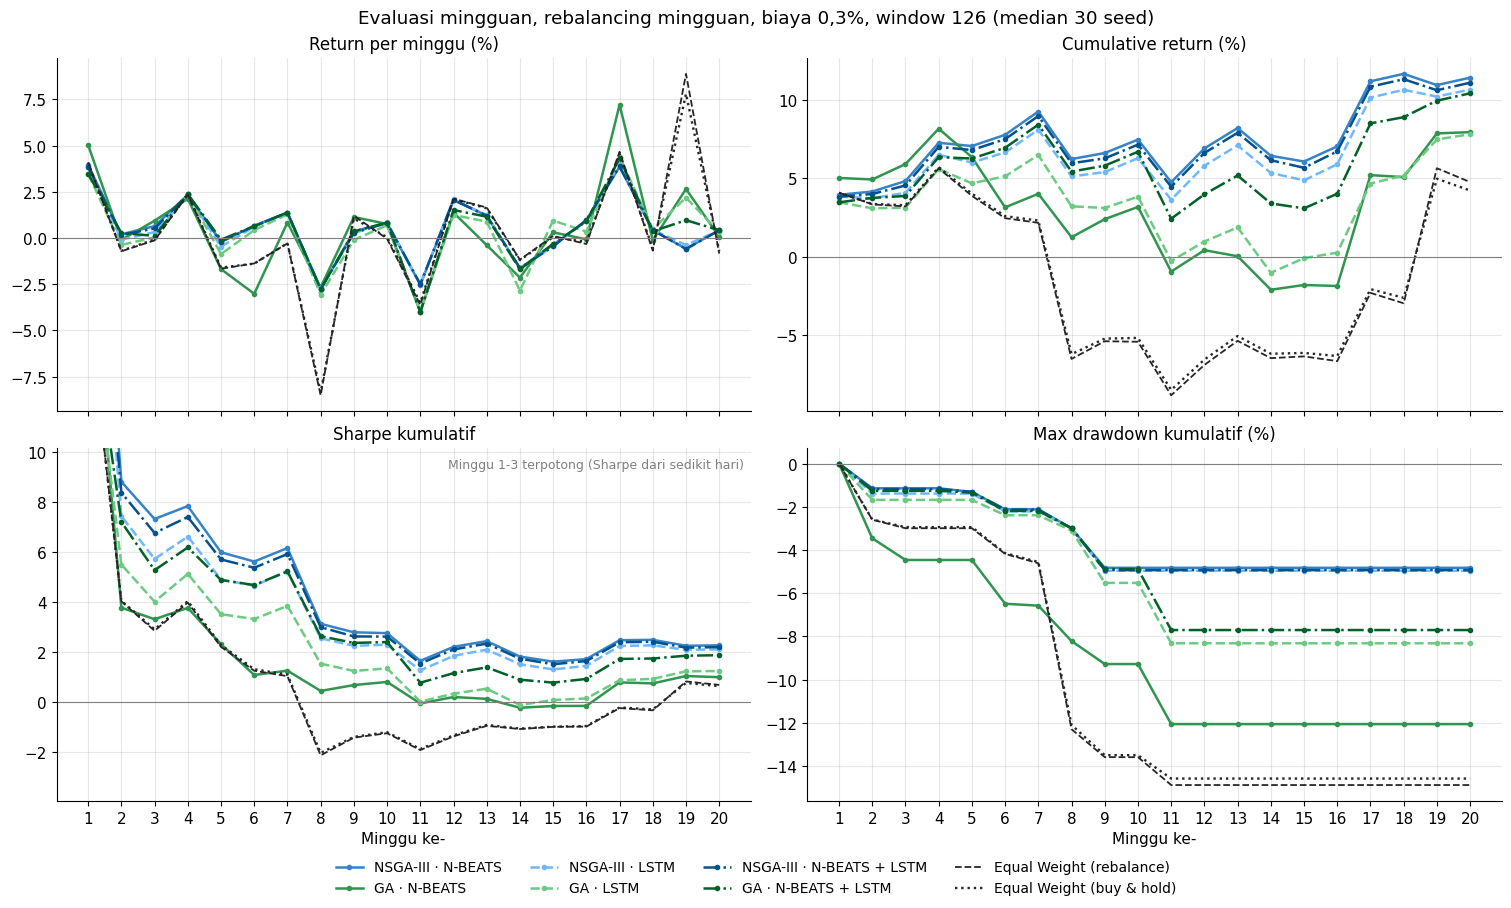

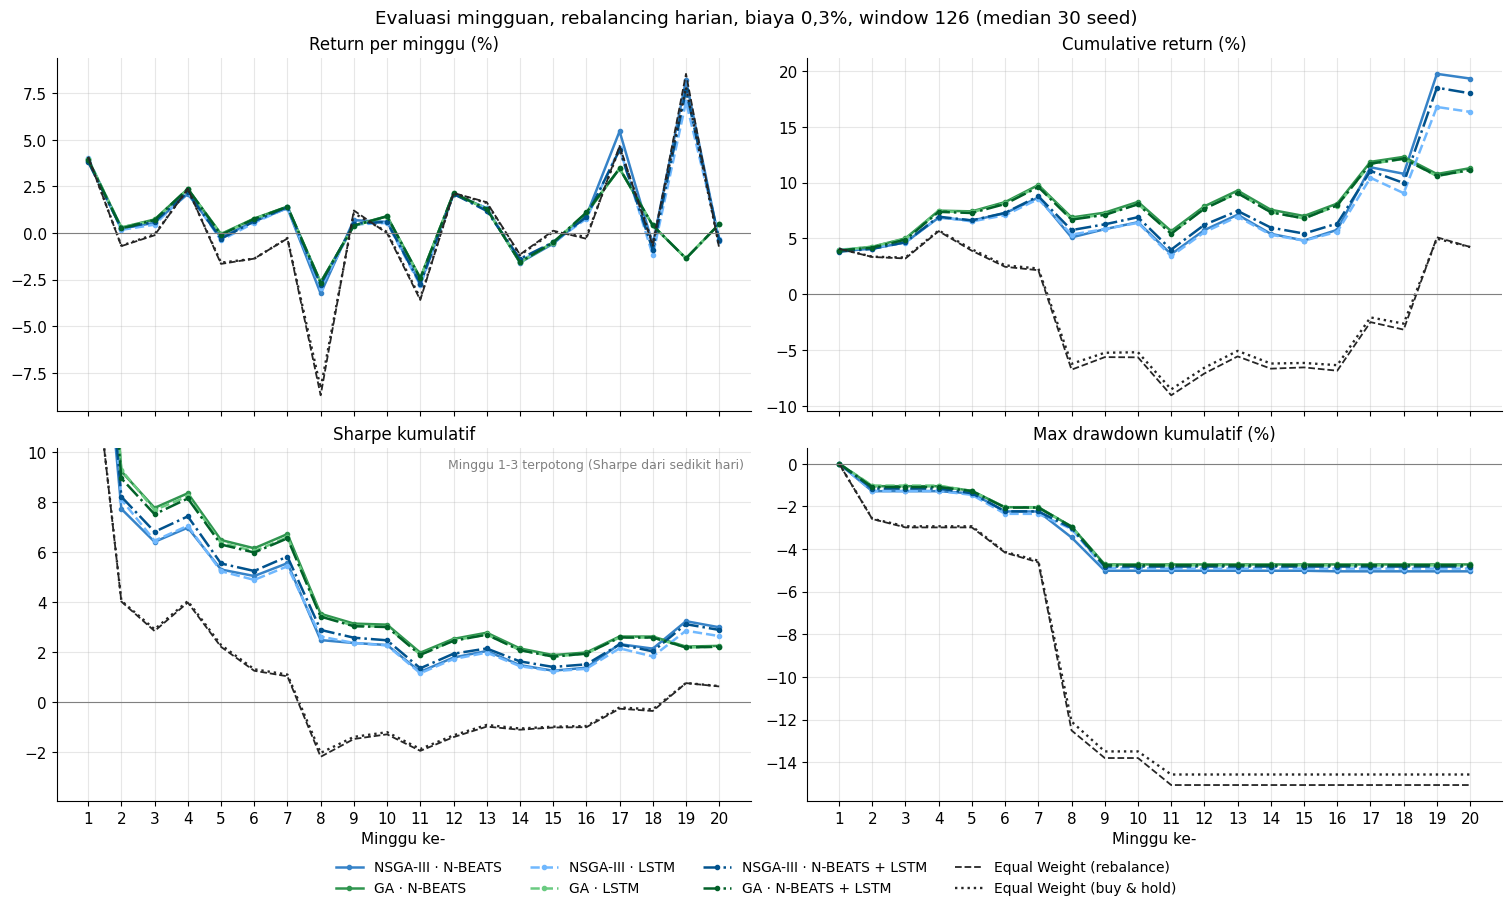

In [29]:
# Grafik evaluasi mingguan (median antar seed): biaya 0,3%, window tengah
PANEL_MINGGUAN = [("Return Minggu (%)", "Return per minggu (%)", 1), ("Total Return (%)", "Cumulative return (%)", 1),
                  ("Sharpe", "Sharpe kumulatif", 1), ("Max Drawdown", "Max drawdown kumulatif (%)", 100)]

for freq in FREQUENCIES:

    sub = mingguan_median[(mingguan_median["Frekuensi"] == freq) & (mingguan_median["Biaya"] == "dengan_biaya")]
    sub = sub[(sub["Window"] == WINDOWS[1]) | sub["Window"].isna()]

    fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, layout="constrained")

    for ax, (kolom, judul, skala) in zip(axes.flat, PANEL_MINGGUAN):

        for model in MODELS:
            for algorithm in ["NSGA-III", "GA"]:
                g = sub[(sub["Algoritma"] == algorithm) & (sub["Model"] == model)]
                ax.plot(g["Minggu"], g[kolom] * skala, color=WARNA[f"{algorithm} · {NAMA[model]}"], linestyle=GARIS[model],
                        marker="o", markersize=3, label=f"{algorithm} · {NAMA[model]}")

        for nama, gaya in GAYA_BENCHMARK.items():
            g = sub[sub["Algoritma"] == nama]
            ax.plot(g["Minggu"], g[kolom] * skala, label=nama, **gaya)

        ax.axhline(0, color="grey", linewidth=0.8)
        ax.set_title(judul)
        ax.grid(True, alpha=0.3)

    # Sharpe 1-3 minggu pertama dihitung dari sedikit hari sehingga ekstrem; sumbu-y mengikuti minggu ke-4 dst
    stabil = sub.loc[sub["Minggu"] >= 4, "Sharpe"]
    axes[1, 0].set_ylim(stabil.min() - 0.5, stabil.max() + 0.5)
    axes[1, 0].text(0.99, 0.97, "Minggu 1-3 terpotong (Sharpe dari sedikit hari)", transform=axes[1, 0].transAxes, ha="right", va="top",
                    fontsize=9, color="grey")

    for ax in axes[1]:
        ax.set_xlabel("Minggu ke-")
        ax.set_xticks(range(1, len(AKHIR_MINGGU) + 1))

    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4, frameon=False)
    fig.suptitle(f"Evaluasi mingguan, rebalancing {freq}, biaya 0,3%, window {WINDOWS[1]} (median {N_SEEDS} seed)")
    simpan_tampil(f"evaluasi_mingguan_{freq}", fig)

## 10. Uji Wilcoxon Signed-Rank (berpasangan per seed)

In [30]:
# Berpasangan per seed: dengan seed sama, NSGA-III dan GA berangkat dari populasi awal yang identik
def paired_wilcoxon(x, y):
    """(W = sum sign(d) R sesuai persamaan 2.82, p dua sisi); selisih nol seluruhnya -> (nan, 1.0)."""

    d = np.asarray(x, dtype=float) - np.asarray(y, dtype=float)

    if np.allclose(d, 0):
        return np.nan, 1.0

    d = d[d != 0]

    return float((np.sign(d) * rankdata(np.abs(d))).sum()), wilcoxon(x, y).pvalue


KONTEKS = ["Model", "Frekuensi", "Mode", "Biaya", "Window"]

wilcoxon_rows = []


def tambah_perbandingan(label, a, b, konteks):
    """a dan b adalah dua sub-DataFrame metrics_df yang dipasangkan per seed."""

    a = a.sort_values("Seed")
    b = b.sort_values("Seed")

    assert len(a) == len(b) and (a["Seed"].values == b["Seed"].values).all()

    lengkap = {kolom: konteks.get(kolom, "-") for kolom in KONTEKS}

    for column in METRIC_COLUMNS:

        x, y = a[column].values, b[column].values
        statistic, p_value = paired_wilcoxon(x, y)

        wilcoxon_rows.append({
            "Perbandingan": label,
            **lengkap,
            "Metrik": column,
            "Median A": np.median(x),
            "Median B": np.median(y),
            "Selisih Median": np.median(x) - np.median(y),
            "Statistik W": statistic,
            "p-value": p_value,
            "Signifikan (5%)": "ya" if p_value < 0.05 else "tidak"
        })


def saring(**syarat):
    mask = pd.Series(True, index=metrics_df.index)
    for kolom, nilai in syarat.items():
        mask &= metrics_df[kolom] == nilai
    return metrics_df[mask]


# 1. NSGA-III vs GA
for model, freq, mode, biaya in COMBINATIONS:
    for window in WINDOWS:
        sub = saring(Model=model, Frekuensi=freq, Mode=mode,
                   Biaya=biaya, Window=window)
        tambah_perbandingan(
            "NSGA-III vs GA",
            sub[sub["Algoritma"] == "NSGA-III"], sub[sub["Algoritma"] == "GA"],
            {"Model": model, "Frekuensi": freq, "Mode": mode,
             "Biaya": biaya, "Window": window}
        )

# 2. Antar model forecast: N-BEATS vs LSTM, kombinasi vs masing-masing
for model_a, model_b in [("nbeats", "lstm"), (COMBINED, "nbeats"), (COMBINED, "lstm")]:
    for algorithm in ["NSGA-III", "GA"]:
        for freq, mode, _ in SCENARIOS:
            for biaya in TC_RATES:
                for window in WINDOWS:
                    sub = saring(Algoritma=algorithm, Frekuensi=freq, Mode=mode,
                               Biaya=biaya, Window=window)
                    tambah_perbandingan(
                        f"{model_a} vs {model_b} ({algorithm})",
                        sub[sub["Model"] == model_a], sub[sub["Model"] == model_b],
                        {"Frekuensi": freq, "Mode": mode,
                         "Biaya": biaya, "Window": window}
                    )

# 3. Frekuensi rebalancing: mingguan (t_akhir) vs harian (t+1)
for algorithm in ["NSGA-III", "GA"]:
    for model in MODELS:
        for biaya in TC_RATES:
            for window in WINDOWS:
                sub = saring(Algoritma=algorithm, Model=model,
                           Biaya=biaya, Window=window)
                tambah_perbandingan(
                    f"mingguan vs harian ({algorithm})",
                    sub[(sub["Frekuensi"] == "mingguan") & (sub["Mode"] == "t_akhir")],
                    sub[sub["Frekuensi"] == "harian"],
                    {"Model": model, "Biaya": biaya, "Window": window}
                )

# 4. Dengan vs tanpa biaya transaksi
for algorithm in ["NSGA-III", "GA"]:
    for model, freq, mode in dict.fromkeys(kunci[:3] for kunci in COMBINATIONS):
        for window in WINDOWS:
            sub = saring(Algoritma=algorithm, Model=model, Frekuensi=freq,
                       Mode=mode, Window=window)
            tambah_perbandingan(
                f"dengan vs tanpa biaya ({algorithm})",
                sub[sub["Biaya"] == "dengan_biaya"],
                sub[sub["Biaya"] == "tanpa_biaya"],
                {"Model": model, "Frekuensi": freq,
                 "Mode": mode, "Window": window}
            )

wilcoxon_df = pd.DataFrame(wilcoxon_rows)

for label in wilcoxon_df["Perbandingan"].unique():
    print(f"\n{label}:")
    print(wilcoxon_df[wilcoxon_df["Perbandingan"] == label].to_string(index=False))


NSGA-III vs GA:
  Perbandingan     Model Frekuensi    Mode        Biaya  Window           Metrik    Median A    Median B  Selisih Median  Statistik W      p-value Signifikan (5%)
NSGA-III vs GA    nbeats  mingguan t_akhir dengan_biaya      63           Sharpe    2.537753    1.794600        0.743153        465.0 1.862645e-09              ya
NSGA-III vs GA    nbeats  mingguan t_akhir dengan_biaya      63          Sortino    4.193341    2.900000        1.293341        465.0 1.862645e-09              ya
NSGA-III vs GA    nbeats  mingguan t_akhir dengan_biaya      63     Max Drawdown   -0.060767   -0.129620        0.068853        465.0 1.862645e-09              ya
NSGA-III vs GA    nbeats  mingguan t_akhir dengan_biaya      63         Turnover   10.446669    9.023984        1.422685        465.0 1.862645e-09              ya
NSGA-III vs GA    nbeats  mingguan t_akhir dengan_biaya      63      Final Value 1186.959133 1185.153491        1.805642         79.0 4.279546e-01           tidak
NSGA-

## 11. Visualisasi

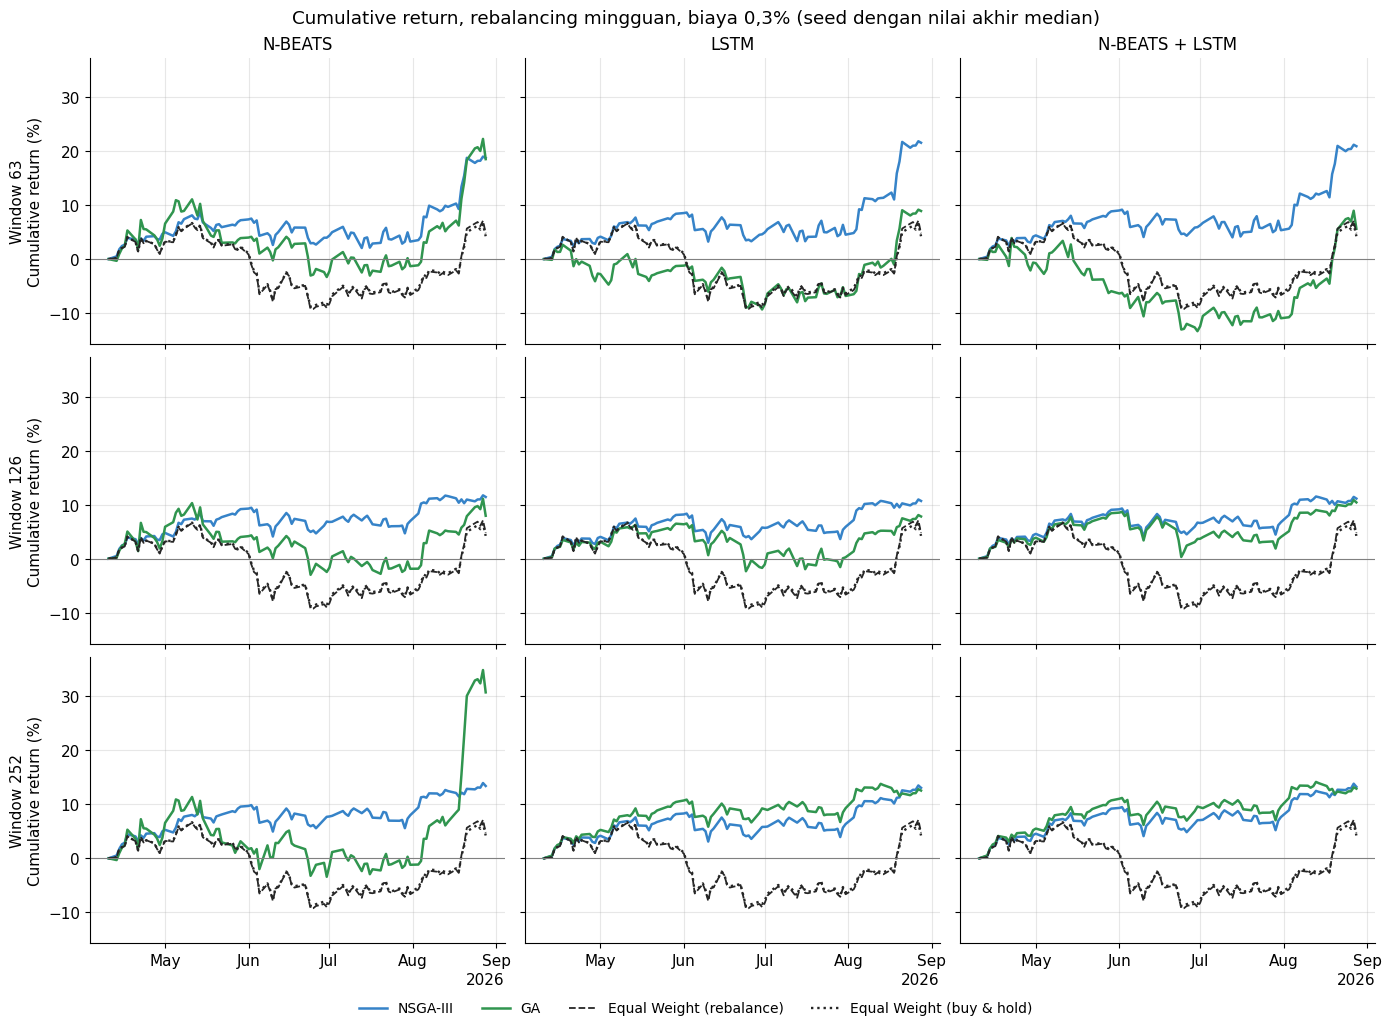

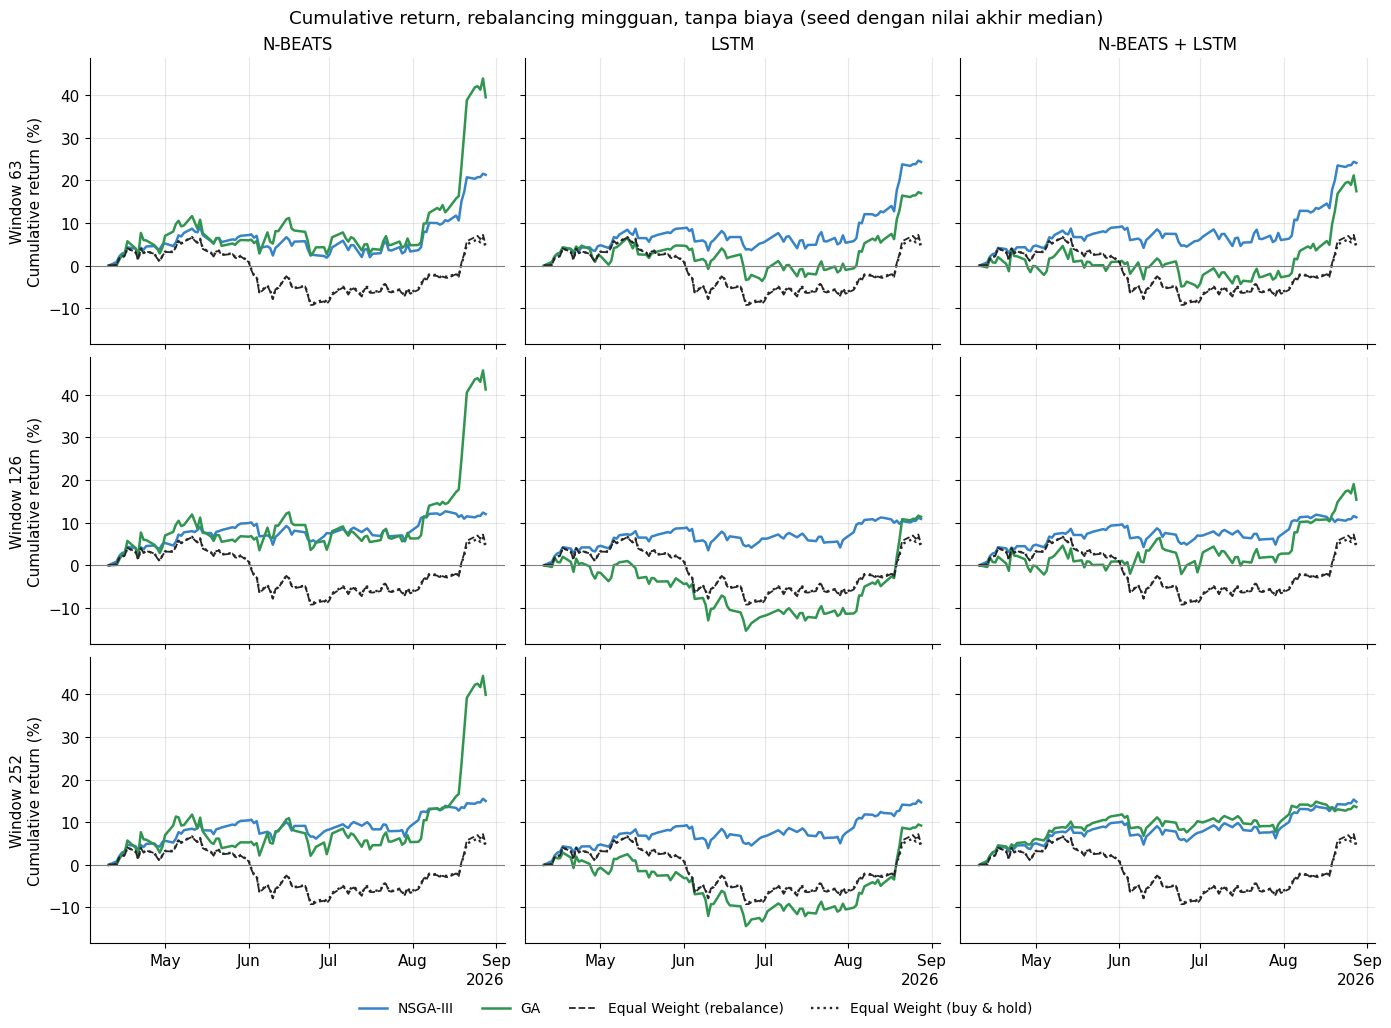

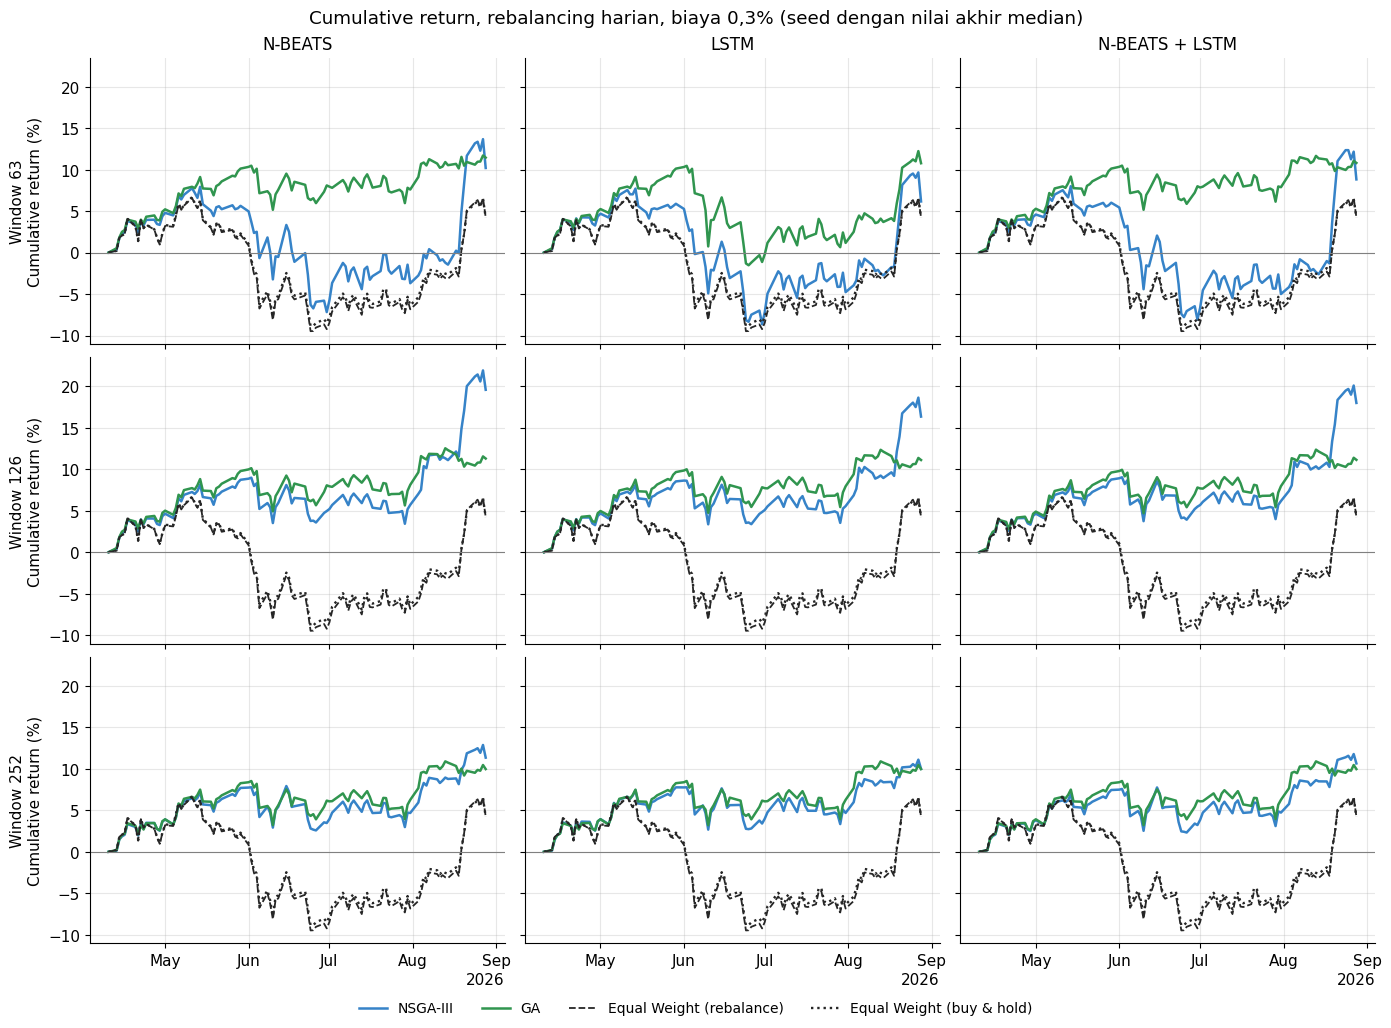

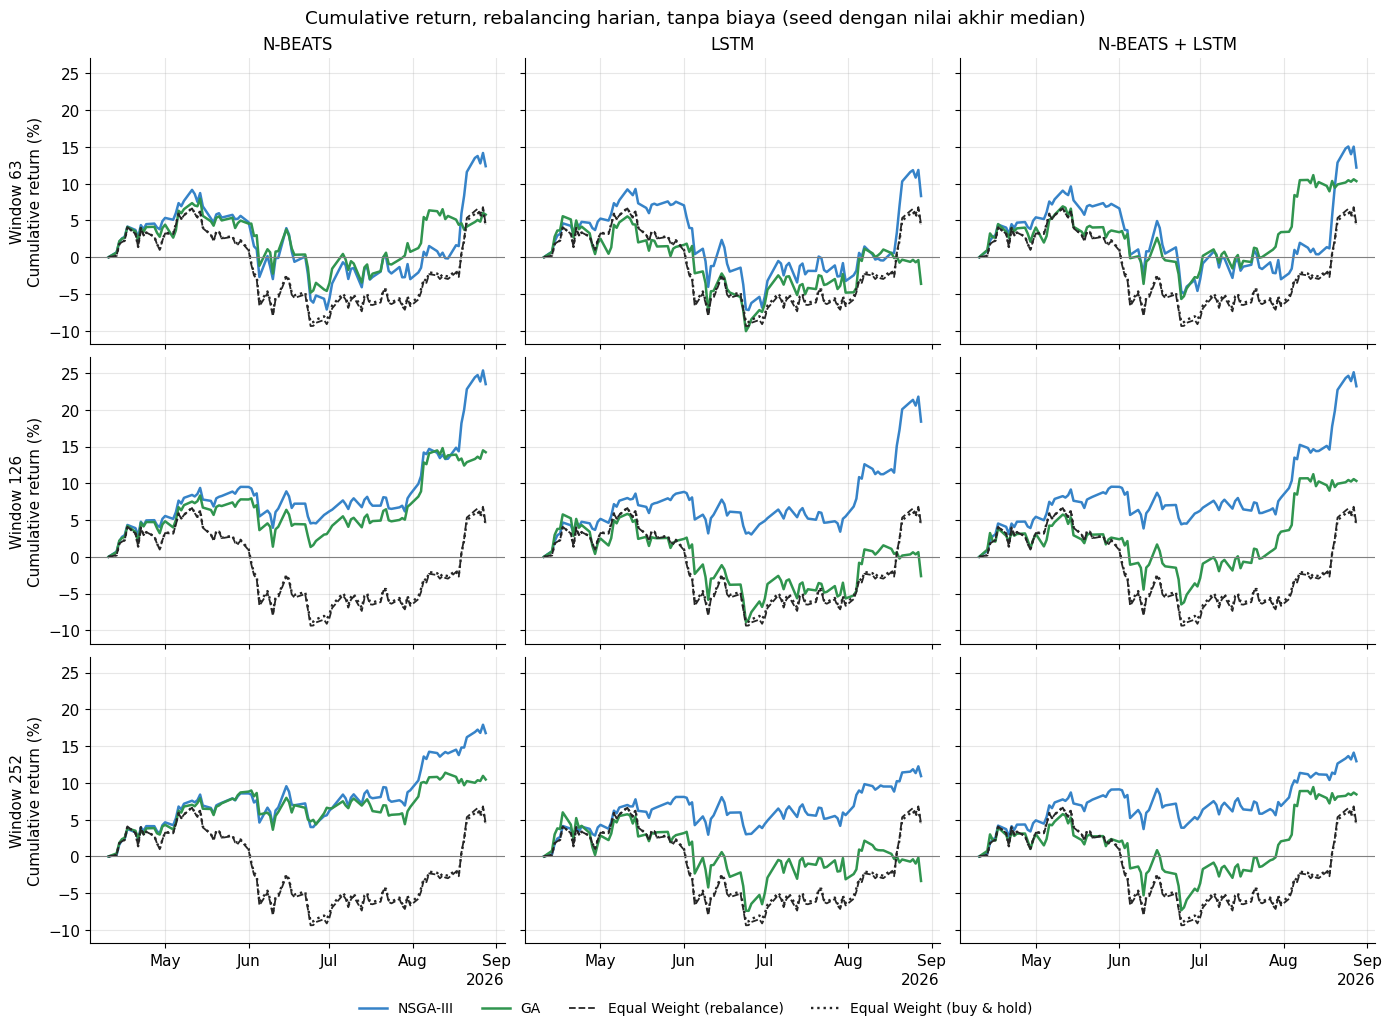

In [31]:
# Cumulative return, seed dengan nilai akhir median; benchmark equal weight
plt.close("all")

MODE_FREQ = {freq: mode for freq, mode, _ in SCENARIOS}


def median_seed(algorithm, model, freq, mode, biaya, window):

    subset = metrics_df[
        (metrics_df["Algoritma"] == algorithm)
        & (metrics_df["Model"] == model)
        & (metrics_df["Frekuensi"] == freq)
        & (metrics_df["Mode"] == mode)
        & (metrics_df["Biaya"] == biaya)
        & (metrics_df["Window"] == window)
    ].sort_values("Final Value").reset_index(drop=True)

    return int(subset.loc[len(subset) // 2, "Seed"])


def cumulative_return(result):
    return (np.asarray(result["daily_values"]) / INITIAL_CAPITAL - 1.0) * 100


for freq in FREQUENCIES:
    for biaya in TC_RATES:

        mode = MODE_FREQ[freq]

        fig, axes = plt.subplots(len(WINDOWS), len(MODELS), figsize=(4.6 * len(MODELS), 3.4 * len(WINDOWS)),
                                 sharex=True, sharey=True, layout="constrained")

        for row, window in enumerate(WINDOWS):
            for col, model in enumerate(MODELS):

                ax = axes[row, col]

                for algorithm in ["NSGA-III", "GA"]:
                    seed = median_seed(algorithm, model, freq, mode, biaya, window)
                    result = backtest_store[(algorithm, model, freq, mode, biaya, window, seed)]
                    ax.plot(result["daily_dates"], cumulative_return(result), color=WARNA[algorithm], label=algorithm)

                for nama, gaya in GAYA_BENCHMARK.items():
                    result = benchmark_results[(freq, biaya, nama)]
                    ax.plot(result["daily_dates"], cumulative_return(result), label=nama, **gaya)

                ax.axhline(0, color="grey", linewidth=0.8)
                ax.grid(True, alpha=0.3)

                if row == 0:
                    ax.set_title(NAMA[model])
                if col == 0:
                    ax.set_ylabel(f"Window {window}\nCumulative return (%)")

        sumbu_bulanan(axes[-1, 0])
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4, frameon=False)
        fig.suptitle(f"Cumulative return, rebalancing {freq}, {NAMA[biaya]} (seed dengan nilai akhir median)")
        simpan_tampil(f"cumulative_return_{freq}_{biaya}", fig)

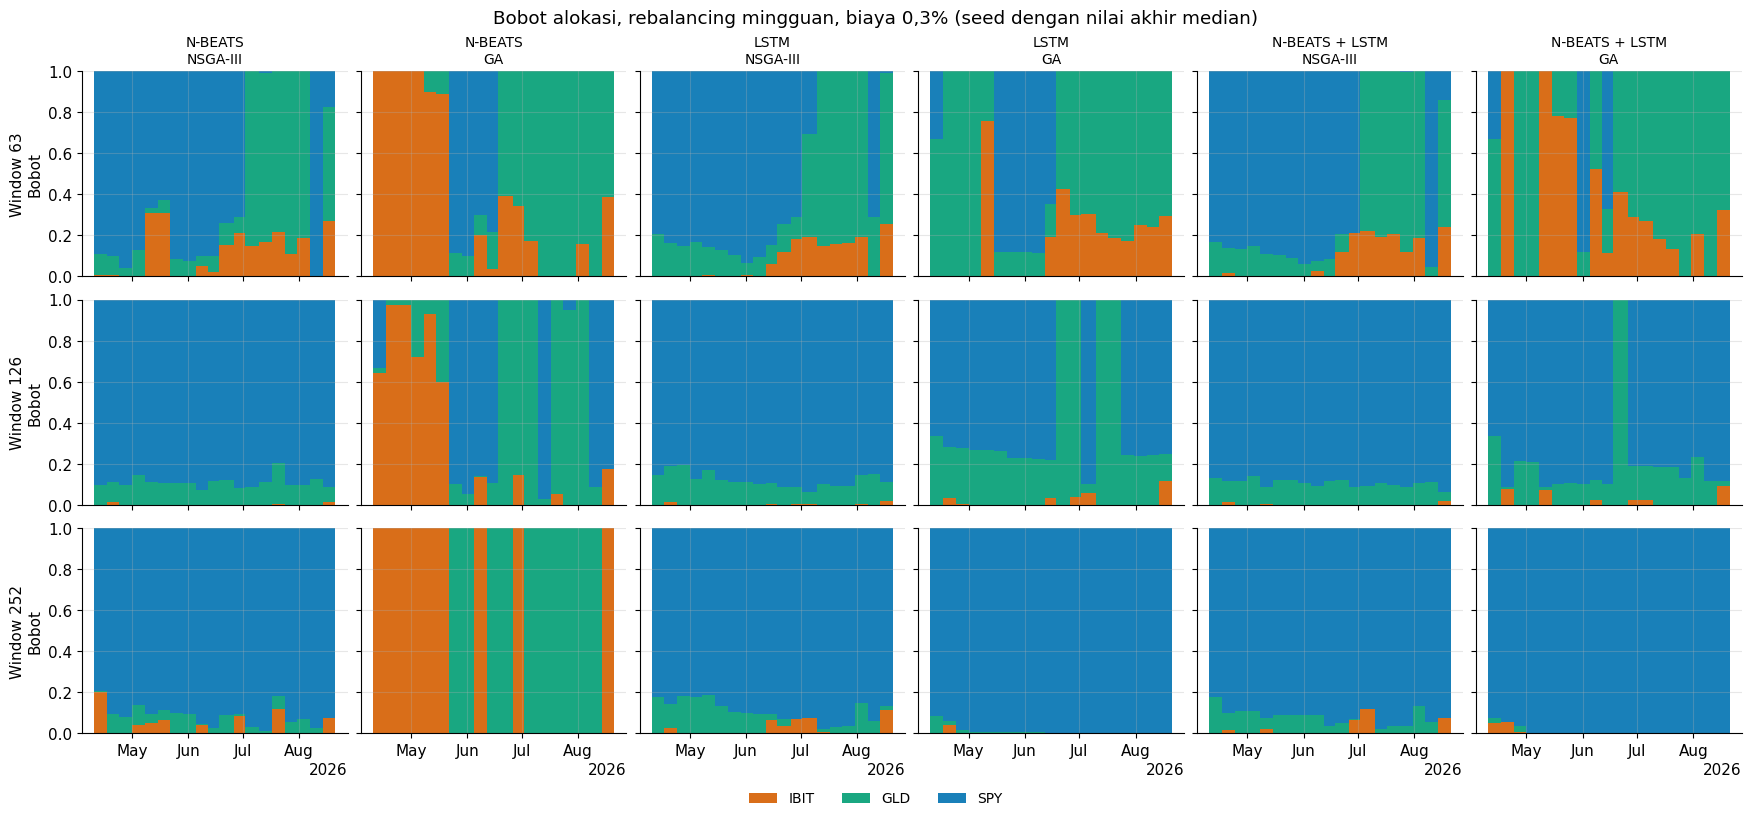

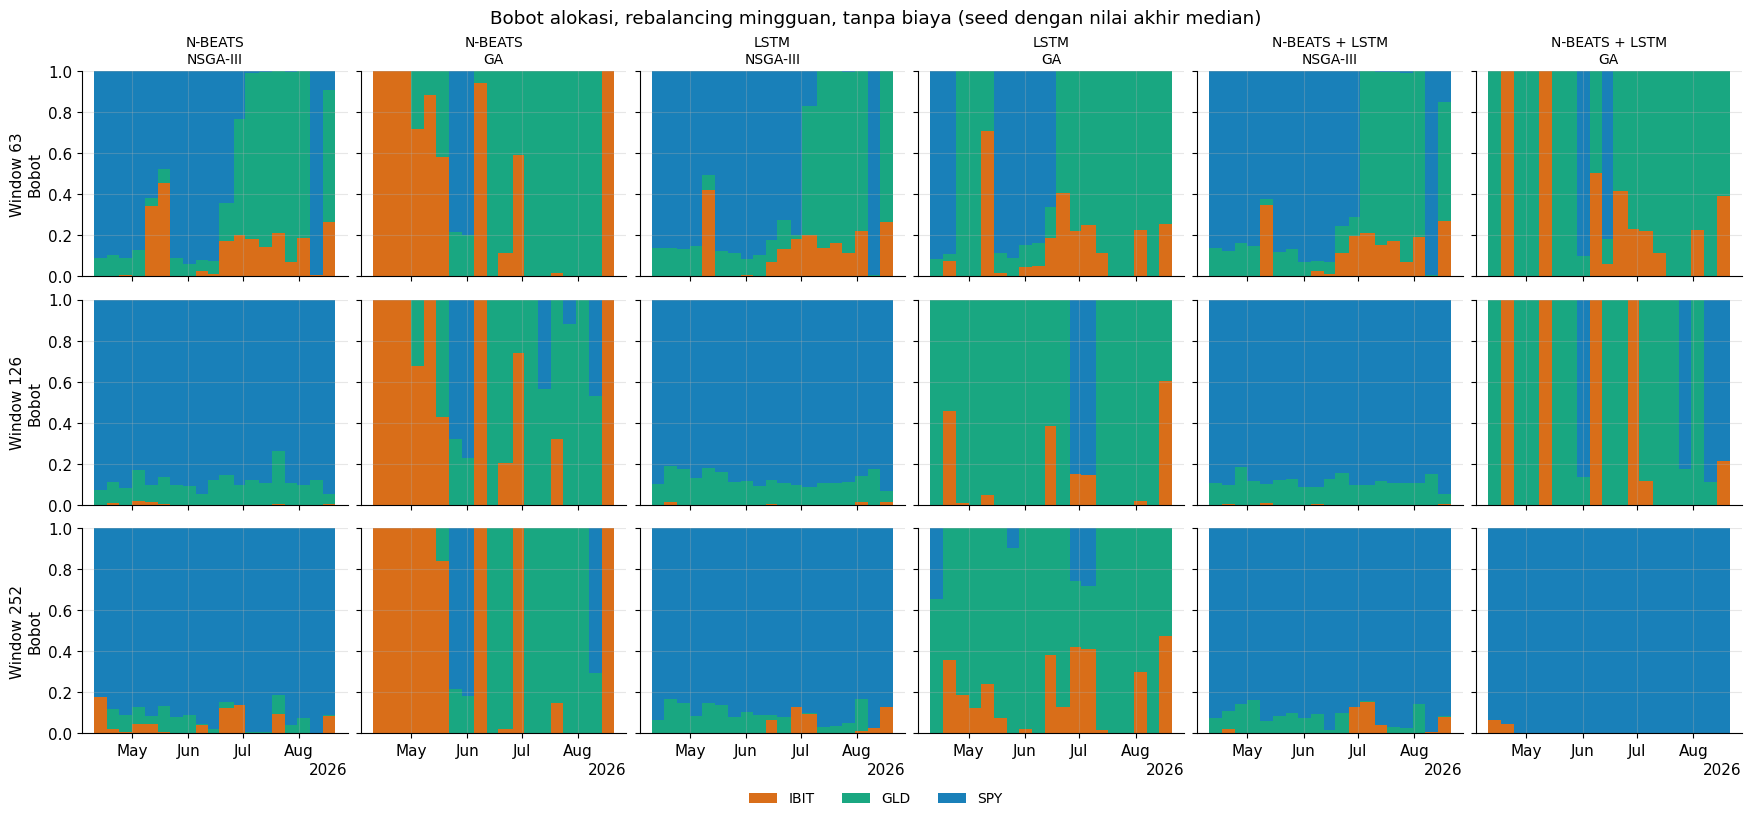

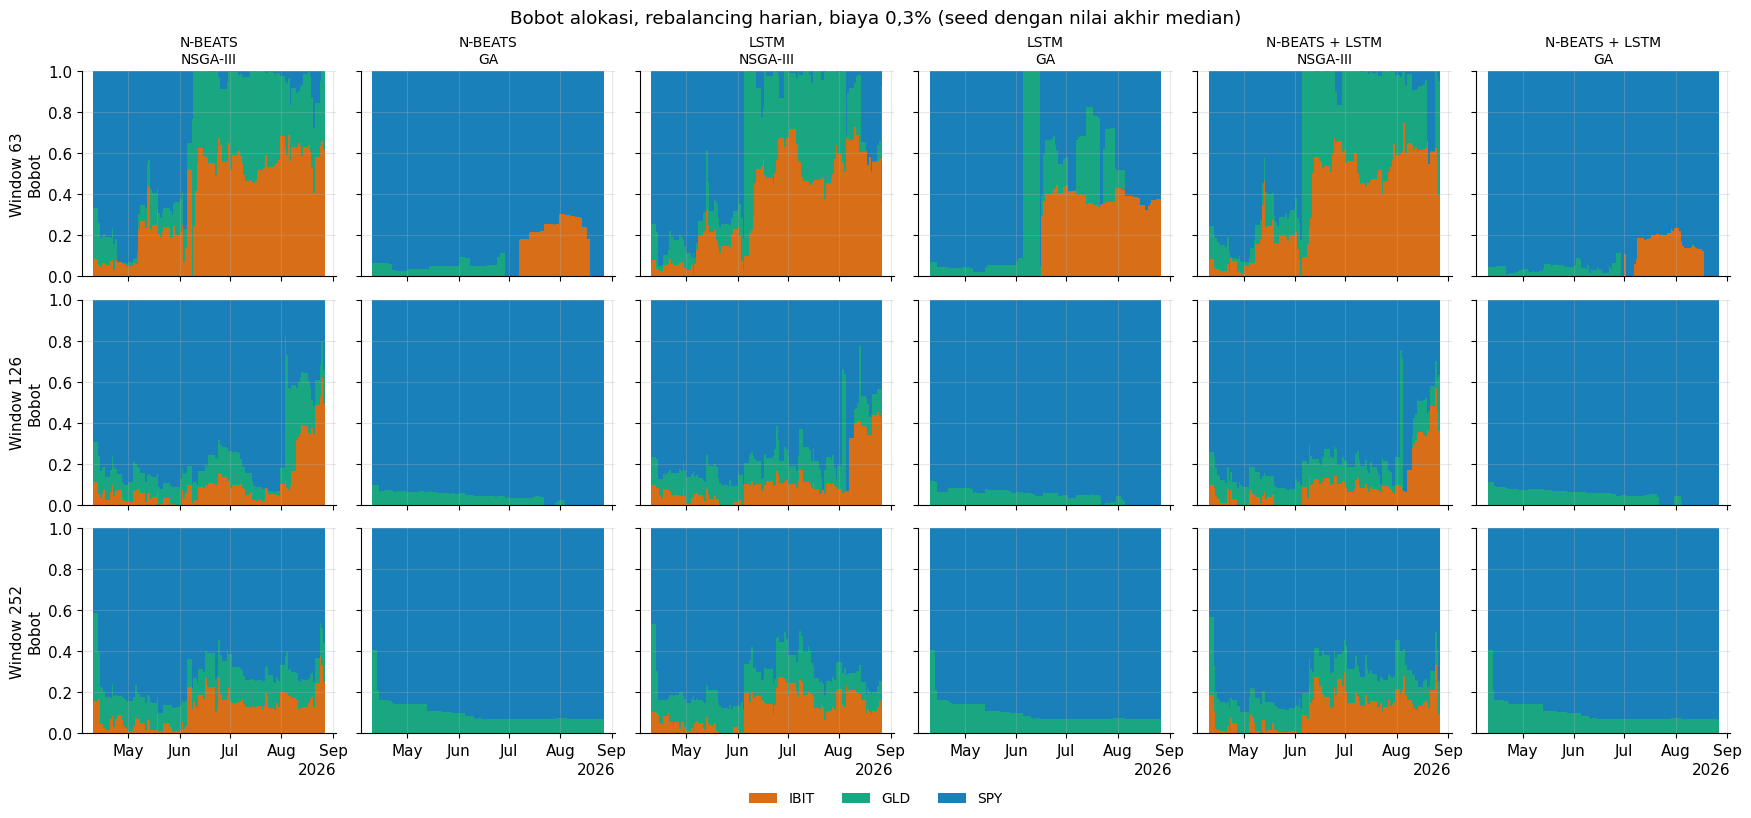

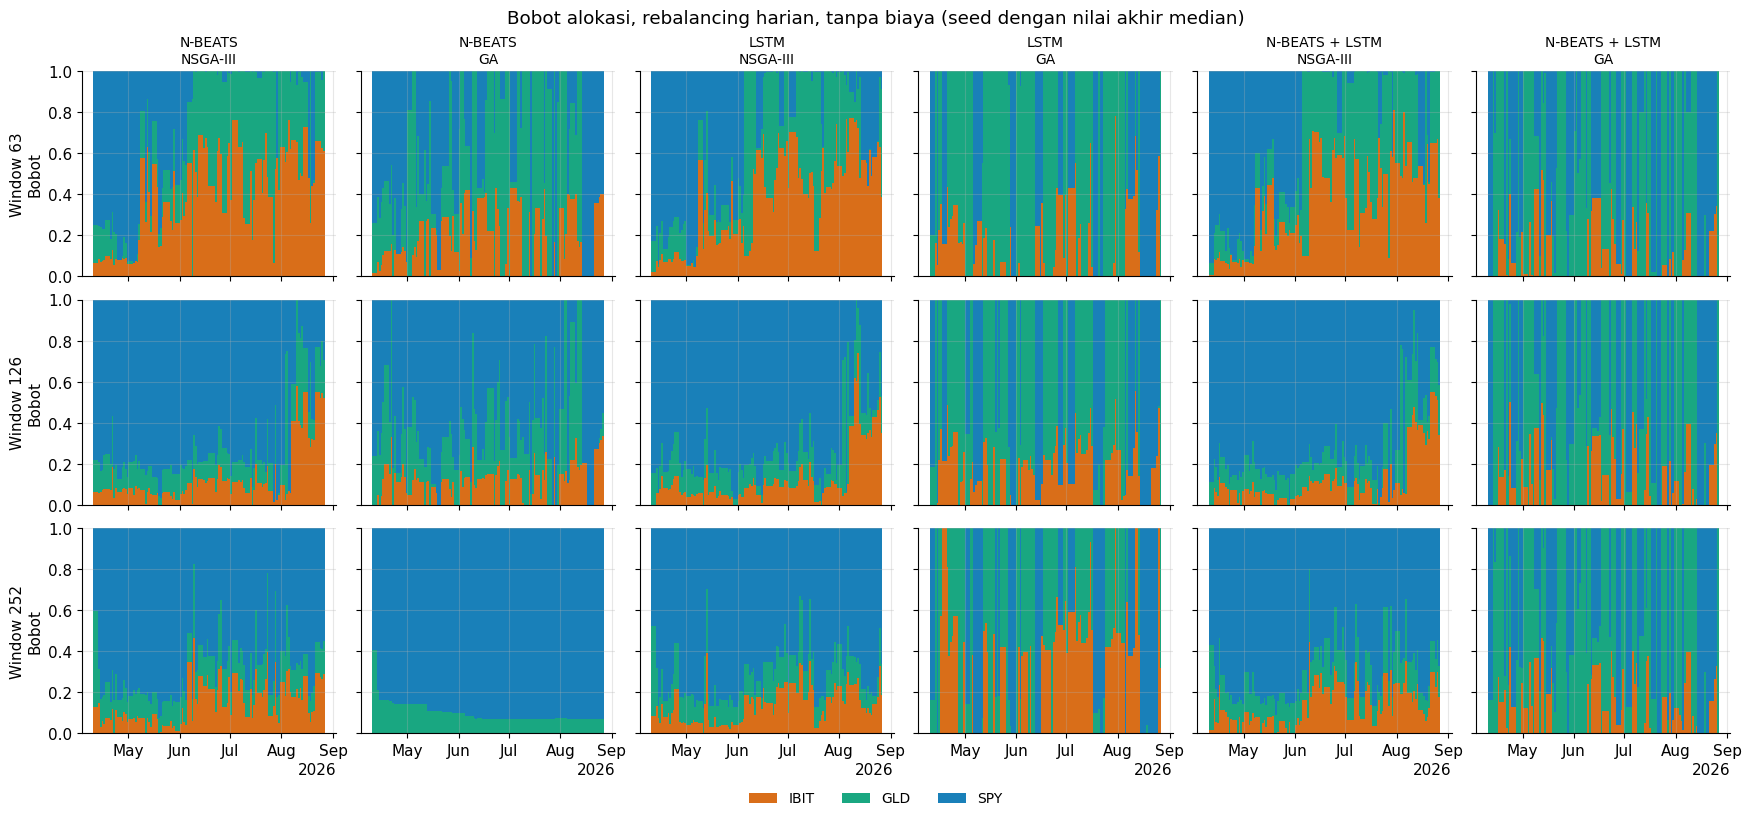

In [32]:
# Pergerakan bobot alokasi, seed dengan nilai akhir median
for freq, mode, _ in SCENARIOS:
    for biaya in TC_RATES:

        kolom = [(model, algorithm) for model in MODELS for algorithm in ["NSGA-III", "GA"]]

        fig, axes = plt.subplots(len(WINDOWS), len(kolom), figsize=(2.9 * len(kolom), 2.7 * len(WINDOWS)),
                                 sharex=True, sharey=True, layout="constrained")

        for row, window in enumerate(WINDOWS):
            for col, (model, algorithm) in enumerate(kolom):

                ax = axes[row, col]
                seed = median_seed(algorithm, model, freq, mode, biaya, window)
                history = backtest_store[(algorithm, model, freq, mode, biaya, window, seed)]["history"]

                ax.stackplot(history["Rebalance Date"], *[history[f"w_{asset}"] for asset in ASSETS],
                             labels=ASSETS, colors=[WARNA[a] for a in ASSETS], alpha=0.9, step="post")
                ax.set_ylim(0, 1)
                ax.grid(True, alpha=0.3)

                if row == 0:
                    ax.set_title(f"{NAMA[model]}\n{algorithm}", fontsize=10)
                if col == 0:
                    ax.set_ylabel(f"Window {window}\nBobot")

        sumbu_bulanan(axes[-1, 0])
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
        fig.suptitle(f"Bobot alokasi, rebalancing {freq}, {NAMA[biaya]} (seed dengan nilai akhir median)")
        simpan_tampil(f"bobot_alokasi_{freq}_{biaya}", fig)

Ukuran Pareto front       : 168
Bobot entropi per objektif: [0.1193 0.4971 0.1548 0.2289]
Solusi terpilih           : {'IBIT': np.float64(0.0008), 'GLD': np.float64(0.0824), 'SPY': np.float64(0.9169)}


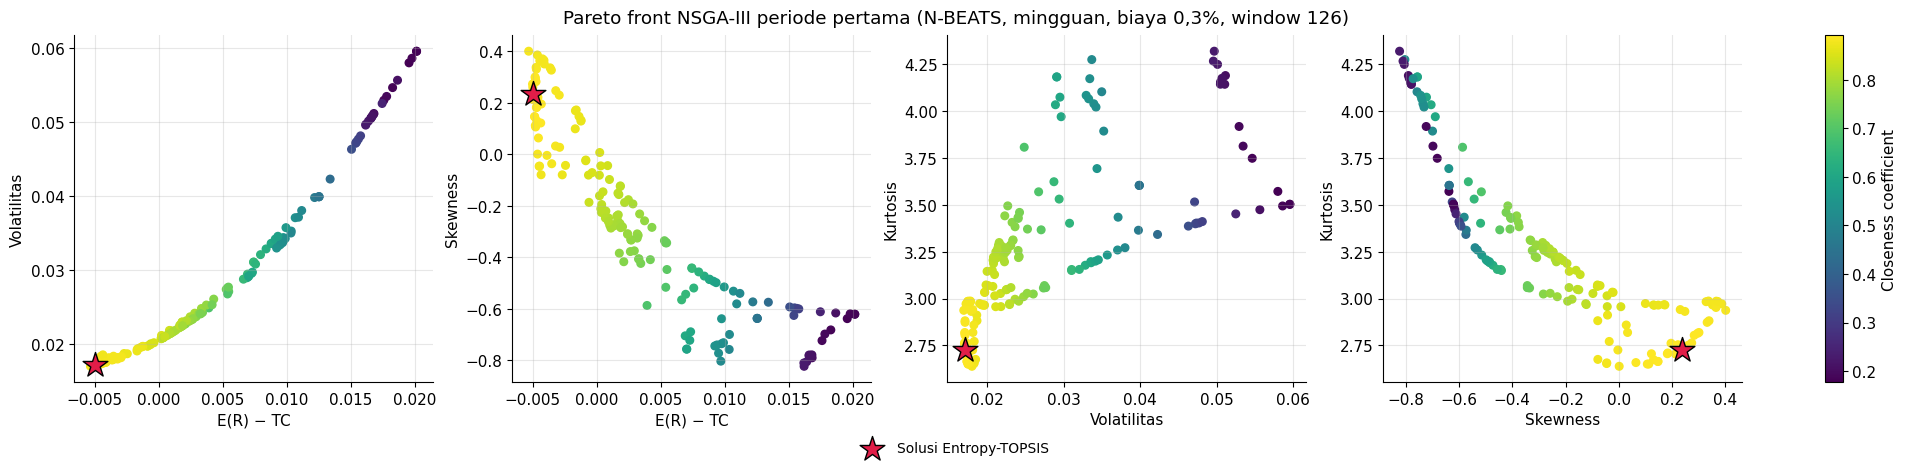

In [33]:
# Pareto front periode rebalancing pertama, NSGA-III seed 0; sumbu ditampilkan dalam arah aslinya (E(R) - TC dan skewness dimaksimumkan)
MIDDLE_WINDOW = WINDOWS[len(WINDOWS) // 2]
PARETO_MODEL, PARETO_FREQ, PARETO_MODE, PARETO_BIAYA = COMBINATIONS[0]

LABEL_OBJEKTIF = ["E(R) − TC", "Volatilitas", "Skewness", "Kurtosis"]
TANDA_OBJEKTIF = np.array([-1, 1, -1, 1])
PASANGAN = [(0, 1), (0, 2), (1, 3), (2, 3)]

example = backtest_store[
    ("NSGA-III", PARETO_MODEL, PARETO_FREQ, PARETO_MODE, PARETO_BIAYA, MIDDLE_WINDOW, 0)
]["extras"][0]

pareto_F = example["pareto_F"]
pareto_X = example["pareto_X"]

chosen, topsis_weights, closeness = entropy_topsis(pareto_F)

print(f"Ukuran Pareto front       : {len(pareto_F)}")
print(f"Bobot entropi per objektif: {np.round(topsis_weights, 4)}")
print(f"Solusi terpilih           : {dict(zip(ASSETS, np.round(pareto_X[chosen], 4)))}")

tampil_F = pareto_F * TANDA_OBJEKTIF

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")

for ax, (i, j) in zip(axes, PASANGAN):
    titik = ax.scatter(tampil_F[:, i], tampil_F[:, j], c=closeness, cmap="viridis", s=30)
    ax.scatter(tampil_F[chosen, i], tampil_F[chosen, j], marker="*", s=350, color="#e11d48",
               edgecolor="black", label="Solusi Entropy-TOPSIS", zorder=5)
    ax.set_xlabel(LABEL_OBJEKTIF[i])
    ax.set_ylabel(LABEL_OBJEKTIF[j])
    ax.grid(True, alpha=0.3)

fig.colorbar(titik, ax=axes, label="Closeness coefficient", fraction=0.02)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", frameon=False)
fig.suptitle(f"Pareto front NSGA-III periode pertama ({NAMA[PARETO_MODEL]}, {PARETO_FREQ}, "
             f"{NAMA[PARETO_BIAYA]}, window {MIDDLE_WINDOW})")
simpan_tampil("pareto_front", fig)

### Konveksitas Pareto Front (unsupported point tidak bisa dicapai GA dengan skalarisasi linier)

In [34]:
# Cek supported point Pareto front lewat linear programming
from scipy.optimize import linprog


def supported_mask(F, tol=1e-9):
    """True jika titik ke-k meminimumkan sum(lambda * f) untuk suatu lambda >= 0."""

    F = np.atleast_2d(np.asarray(F, dtype=float))

    low, high = F.min(axis=0), F.max(axis=0)
    Z = (F - low) / np.where(high - low <= EPS, 1.0, high - low)

    n_obj = Z.shape[1]
    mask = np.zeros(len(Z), dtype=bool)

    for k in range(len(Z)):
        hasil = linprog(
            np.zeros(n_obj), A_ub=Z[k] - Z, b_ub=np.full(len(Z), tol),
            A_eq=np.ones((1, n_obj)), b_eq=[1.0],
            bounds=[(0, 1)] * n_obj, method="highs"
        )
        mask[k] = hasil.status == 0

    return mask


konveks_rows = []

for model, freq, mode, biaya in COMBINATIONS:
    for window in WINDOWS:

        extras = backtest_store[
            ("NSGA-III", model, freq, mode, biaya, window, 0)
        ]["extras"]

        tak_terdukung, topsis_tak = [], []

        for extra in extras:
            mask = supported_mask(extra["pareto_F"])
            tak_terdukung.append((~mask).mean() * 100)
            topsis_tak.append(not mask[entropy_topsis(extra["pareto_F"])[0]])

        tak_terdukung = np.array(tak_terdukung)

        konveks_rows.append({
            "Model": model, "Frekuensi": freq, "Mode": mode,
            "Biaya": biaya, "Window": window,
            "Periode": len(extras),
            "Ukuran front": np.mean([len(e["pareto_F"]) for e in extras]),
            "Tak terdukung (%)": tak_terdukung.mean(),
            "Tak terdukung maks (%)": tak_terdukung.max(),
            "Periode non-konveks (%)": (tak_terdukung > 0).mean() * 100,
            "TOPSIS tak terdukung (%)": np.mean(topsis_tak) * 100
        })

konveksitas_df = pd.DataFrame(konveks_rows)

print("Pareto front NSGA-III seed 0, seluruh periode test (Tak terdukung = unsupported point):")
print(konveksitas_df.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

Pareto front NSGA-III seed 0, seluruh periode test (Tak terdukung = unsupported point):
    Model Frekuensi    Mode        Biaya  Window  Periode  Ukuran front  Tak terdukung (%)  Tak terdukung maks (%)  Periode non-konveks (%)  TOPSIS tak terdukung (%)
   nbeats  mingguan t_akhir dengan_biaya      63       20         168.0               39.5                    63.7                    100.0                       0.0
   nbeats  mingguan t_akhir dengan_biaya     126       20         168.0               36.3                    66.7                    100.0                       0.0
   nbeats  mingguan t_akhir dengan_biaya     252       20         168.0               31.5                    61.3                    100.0                       0.0
   nbeats  mingguan t_akhir  tanpa_biaya      63       20         168.0               39.2                    67.3                    100.0                       5.0
   nbeats  mingguan t_akhir  tanpa_biaya     126       20         168.0           

Supported point    : 139 dari 168
Solusi TOPSIS      : supported
Solusi GA unik     : 92 dari 165 λ


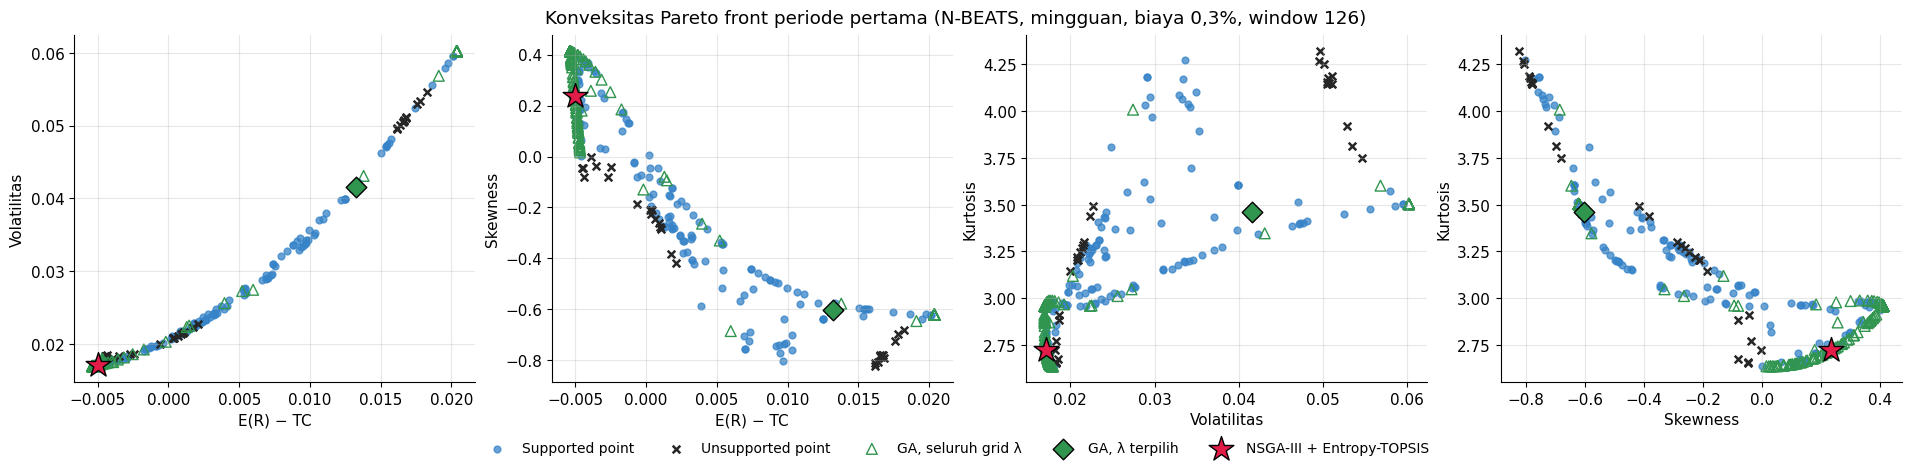

In [35]:
# Pareto front periode pertama: supported vs unsupported point, solusi GA untuk seluruh grid λ
data_contoh = SKEMA[PARETO_FREQ]
rate_contoh = TC_RATES[PARETO_BIAYA]

masukan = (
    data_contoh["r_hat_test"][(PARETO_MODEL, PARETO_MODE)][0],
    np.full(N_ASSETS, 1.0 / N_ASSETS),
    *data_contoh["moments_test"][MIDDLE_WINDOW][0]
)

lambda_terbaik = best_lambda[(PARETO_MODEL, PARETO_FREQ, PARETO_MODE, PARETO_BIAYA, MIDDLE_WINDOW)]

ga_F = np.vstack([
    evaluate_objectives(make_ga_solver(lam, rate=rate_contoh)(*masukan, 0)[0], *masukan, rate_contoh)
    for lam in LAMBDA_GRID
])

ga_terbaik_F = evaluate_objectives(
    make_ga_solver(lambda_terbaik, rate=rate_contoh)(*masukan, 0)[0], *masukan, rate_contoh)

terdukung = supported_mask(pareto_F)

print(f"Supported point    : {terdukung.sum()} dari {len(pareto_F)}")
print(f"Solusi TOPSIS      : {'supported' if terdukung[chosen] else 'unsupported (tidak bisa dicapai GA)'}")
print(f"Solusi GA unik     : {len(np.unique(ga_F.round(6), axis=0))} dari {len(LAMBDA_GRID)} λ")

tampil = {nama: F * TANDA_OBJEKTIF for nama, F in
          [("pareto", pareto_F), ("ga", ga_F), ("ga_terbaik", ga_terbaik_F)]}

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")

for ax, (i, j) in zip(axes, PASANGAN):
    F = tampil["pareto"]
    ax.scatter(F[terdukung, i], F[terdukung, j], s=24, color=WARNA["NSGA-III"], alpha=0.75, label="Supported point")
    ax.scatter(F[~terdukung, i], F[~terdukung, j], s=30, marker="x", color="#262626", label="Unsupported point")
    ax.scatter(tampil["ga"][:, i], tampil["ga"][:, j], s=60, marker="^", facecolors="none",
               edgecolors=WARNA["GA"], label="GA, seluruh grid λ")
    ax.scatter(tampil["ga_terbaik"][:, i], tampil["ga_terbaik"][:, j], s=110, marker="D", color=WARNA["GA"],
               edgecolor="black", label="GA, λ terpilih", zorder=5)
    ax.scatter(F[chosen, i], F[chosen, j], s=350, marker="*", color="#e11d48", edgecolor="black",
               label="NSGA-III + Entropy-TOPSIS", zorder=6)
    ax.set_xlabel(LABEL_OBJEKTIF[i])
    ax.set_ylabel(LABEL_OBJEKTIF[j])
    ax.grid(True, alpha=0.3)

fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, frameon=False)
fig.suptitle(f"Konveksitas Pareto front periode pertama ({NAMA[PARETO_MODEL]}, {PARETO_FREQ}, "
             f"{NAMA[PARETO_BIAYA]}, window {MIDDLE_WINDOW})")
simpan_tampil("pareto_konveksitas", fig)

### Konvergensi NSGA-III dan GA (hypervolume per generasi; GA dibandingkan minimum grid simpleks 0,5%)

HV NSGA-III generasi 50 relatif terhadap generasi 100 (%):
             mean    min     max
Frekuensi                       
mingguan   100.19  99.12  102.03
harian     100.06  99.23  100.72

GA dibandingkan minimum grid simpleks 0,5%:
          Selisih skalar Jarak bobot (%)
                     max             max
Frekuensi                               
mingguan   -3.331356e-07        0.213039
harian      7.771561e-16        0.249269


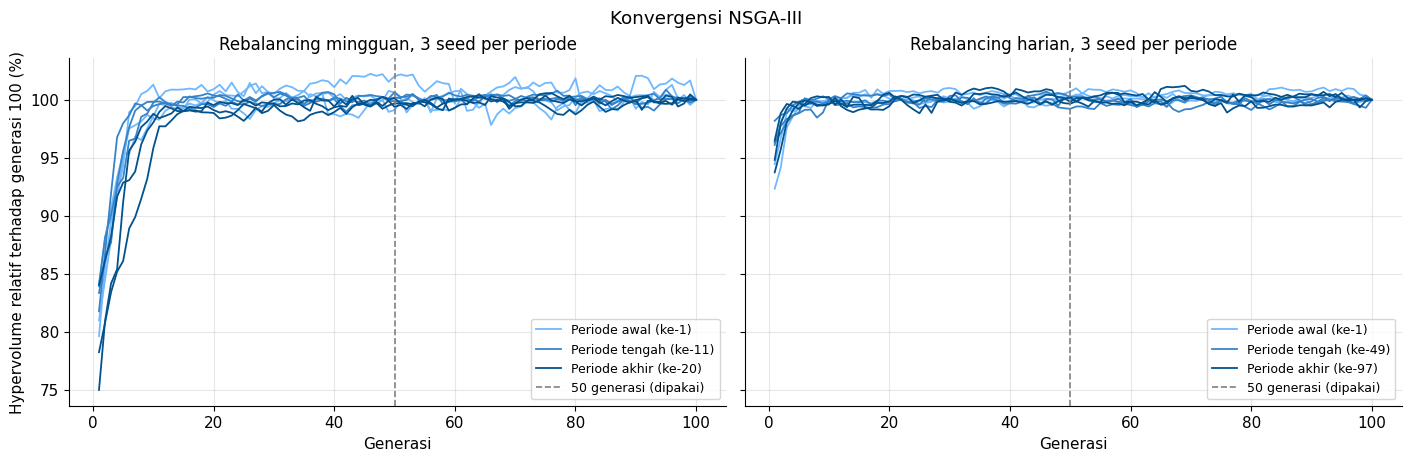

In [36]:
# Konvergensi periode awal, tengah, akhir tiap frekuensi (skenario contoh, 3 seed): HV NSGA-III per generasi dan optimum GA
from pymoo.indicators.hv import HV

GRID_SIMPLEKS = np.array([(i, j, 200 - i - j) for i in range(201) for j in range(201 - i)]) / 200

konvergensi_rows, optimum_ga_rows = [], []

for freq, mode in [("mingguan", "t_akhir"), ("harian", "t+1")]:

    data = SKEMA[freq]
    rate = TC_RATES[PARETO_BIAYA]
    lam = best_lambda[(PARETO_MODEL, freq, mode, PARETO_BIAYA, MIDDLE_WINDOW)]

    # Bobot sebelum transaksi mengikuti jalur backtest NSGA-III seed 0
    riwayat = backtest_store[("NSGA-III", PARETO_MODEL, freq, mode, PARETO_BIAYA, MIDDLE_WINDOW, 0)]["history"]
    bobot = riwayat[[f"w_{a}" for a in ASSETS]].values
    T = len(bobot)

    for t in sorted({0, T // 2, T - 1}):

        w_minus = np.full(N_ASSETS, 1.0 / N_ASSETS) if t == 0 else drift_weights(bobot[t - 1], data["realized_test"][t - 1])
        masukan_t = (data["r_hat_test"][(PARETO_MODEL, mode)][t], w_minus,
                     *data["moments_test"][MIDDLE_WINDOW][t])

        fronts = {}
        for seed in range(3):
            algorithm = NSGA3(
                ref_dirs=REF_DIRS, pop_size=POP_SIZE, repair=SimplexRepair(),
                crossover=SBX(prob=0.9, eta=15), mutation=PM(eta=20), eliminate_duplicates=True
            )
            hasil = minimize(MVSKProblem(*masukan_t, rate=rate), algorithm, ("n_gen", 2 * N_GEN),
                             seed=seed, save_history=True, verbose=False)
            fronts[seed] = [h.pop.get("F")[NonDominatedSorting().do(h.pop.get("F"), only_non_dominated_front=True)]
                            for h in hasil.history]

        # Normalisasi bersama seluruh seed dan generasi, titik acuan 1,1; HV relatif terhadap generasi 2 x N_GEN
        semua = np.vstack([F for r in fronts.values() for F in r])
        low, high = semua.min(axis=0), semua.max(axis=0)
        span = np.where(high - low <= EPS, 1.0, high - low)
        hv = HV(ref_point=np.full(4, 1.1))

        for seed, r in fronts.items():
            nilai = np.array([hv((F - low) / span) for F in r])
            konvergensi_rows += [
                {"Frekuensi": freq, "Periode": t + 1, "Seed": seed, "Generasi": g + 1,
                 "HV relatif (%)": v / nilai[-1] * 100, "Ukuran front": len(r[g])}
                for g, v in enumerate(nilai)
            ]

        # GA: nilai skalarisasi (lambda terpilih) dibandingkan minimum grid simpleks 0,5%
        low_s, high_s = objective_scales(*masukan_t, rate=rate)
        span_s = np.where(high_s - low_s <= EPS, 1.0, high_s - low_s)
        nilai_grid = ((evaluate_objectives(GRID_SIMPLEKS, *masukan_t, rate) - low_s) / span_s) @ lam
        w_grid = GRID_SIMPLEKS[nilai_grid.argmin()]

        for seed in range(3):
            w_ga = make_ga_solver(lam, rate=rate)(*masukan_t, seed)[0]
            nilai_ga = (((evaluate_objectives(w_ga, *masukan_t, rate) - low_s) / span_s) @ lam)[0]
            optimum_ga_rows.append({
                "Frekuensi": freq, "Periode": t + 1, "Seed": seed,
                "Skalar GA": nilai_ga, "Skalar minimum grid": nilai_grid.min(),
                "Selisih skalar": nilai_ga - nilai_grid.min(),
                "Jarak bobot (%)": np.abs(w_ga - w_grid).sum() / 2 * 100
            })

konvergensi_df = pd.DataFrame(konvergensi_rows)
optimum_ga_df = pd.DataFrame(optimum_ga_rows)

print(f"HV NSGA-III generasi {N_GEN} relatif terhadap generasi {2 * N_GEN} (%):")
print(konvergensi_df[konvergensi_df["Generasi"] == N_GEN].groupby("Frekuensi", sort=False)["HV relatif (%)"]
      .agg(["mean", "min", "max"]).round(2).to_string())
print("\nGA dibandingkan minimum grid simpleks 0,5%:")
print(optimum_ga_df.groupby("Frekuensi", sort=False)[["Selisih skalar", "Jarak bobot (%)"]].agg(["max"]).to_string())

WARNA_PERIODE = ["#70b8fe", "#3683c8", "#01528d"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True, layout="constrained")

for ax, (freq, sub) in zip(axes, konvergensi_df.groupby("Frekuensi", sort=False)):
    for warna, (nama, periode) in zip(WARNA_PERIODE, zip(["awal", "tengah", "akhir"], sorted(sub["Periode"].unique()))):
        for k, (_, kurva) in enumerate(sub[sub["Periode"] == periode].groupby("Seed")):
            ax.plot(kurva["Generasi"], kurva["HV relatif (%)"], color=warna, linewidth=1.3,
                    label=f"Periode {nama} (ke-{periode})" if k == 0 else None)
    ax.axvline(N_GEN, color="grey", linestyle="--", linewidth=1.2, label=f"{N_GEN} generasi (dipakai)")
    ax.set_title(f"Rebalancing {freq}, 3 seed per periode")
    ax.set_xlabel("Generasi")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right", fontsize=9)

axes[0].set_ylabel(f"Hypervolume relatif terhadap generasi {2 * N_GEN} (%)")
fig.suptitle("Konvergensi NSGA-III")
simpan_tampil("konvergensi_nsga3", fig)


## 12. Ekspor Hasil (untuk dashboard Streamlit)

In [37]:
# Ekspor hasil

metrics_df.to_csv("portfolio_metrics_all_seeds.csv", index=False)
summary_table.to_csv("portfolio_metrics_summary.csv", index=False)
wilcoxon_df.to_csv("portfolio_wilcoxon.csv", index=False)
benchmark_df.to_csv("portfolio_benchmark.csv", index=False)
lambda_tuning.to_csv("ga_lambda_tuning.csv", index=False)
comoment_summary.to_csv("comoment_summary.csv", index=False)
konveksitas_df.to_csv("pareto_konveksitas.csv", index=False)
konvergensi_df.to_csv("konvergensi_nsga3.csv", index=False)
optimum_ga_df.to_csv("optimum_ga.csv", index=False)
mingguan_df.to_csv("portfolio_mingguan_all_seeds.csv", index=False)
mingguan_median.to_csv("portfolio_mingguan_median.csv", index=False)
pd.concat([
    SKEMA[freq]["pilihan_test"].rename_axis("Tanggal").reset_index().assign(Frekuensi=freq)
    for freq in FREQUENCIES
]).to_csv("pemilihan_model_kombinasi.csv", index=False)

equity_rows = []
weight_rows = []

LABEL = ["Strategi", "Model", "Frekuensi", "Mode", "Biaya", "Window"]

for model, freq, mode, biaya in COMBINATIONS:

    for window in WINDOWS:
        for algorithm in ["NSGA-III", "GA"]:

            seed = median_seed(algorithm, model, freq, mode, biaya, window)
            result = backtest_store[
                (algorithm, model, freq, mode, biaya, window, seed)
            ]

            nilai = dict(zip(LABEL, [algorithm, model, freq, mode, biaya, window]))

            equity_rows.append(pd.DataFrame({
                **nilai, "Seed": seed,
                "Date": result["daily_dates"], "Value": result["daily_values"]
            }))

            history = result["history"].copy()
            for kolom in reversed(LABEL):
                history.insert(0, kolom, nilai[kolom])
            weight_rows.append(history)

for (freq, biaya, name), result in benchmark_results.items():

    nilai = dict(zip(LABEL, [name, "-", freq, "-", biaya, np.nan]))

    equity_rows.append(pd.DataFrame({
        **nilai, "Seed": 0, "Date": result["daily_dates"], "Value": result["daily_values"]
    }))

    history = result["history"].copy()
    for kolom in reversed(LABEL):
        history.insert(0, kolom, nilai[kolom])
    weight_rows.append(history)

pd.concat(equity_rows, ignore_index=True).to_csv("portfolio_equity.csv", index=False)

# λ setiap run dan periode: GA = λ skalarisasi terpilih di validasi (tetap), NSGA-III = bobot entropi Entropy-TOPSIS
KOLOM_ENTROPI = [f"Entropy {nama}" for nama in OBJECTIVE_NAMES]
lambda_rows = []

for (name, model, freq, mode, biaya, window, seed), result in backtest_store.items():
    history = result["history"]
    lam = (np.tile(best_lambda[(model, freq, mode, biaya, window)], (len(history), 1)) if name == "GA"
           else history[KOLOM_ENTROPI].values)
    lambda_rows.append(pd.DataFrame({
        "Algoritma": name, "Model": model, "Frekuensi": freq, "Mode": mode, "Biaya": biaya,
        "Window": window, "Seed": seed, "Periode": np.arange(1, len(history) + 1),
        "Rebalance Date": history["Rebalance Date"].values,
        **{f"lambda_{k + 1}": lam[:, k] for k in range(4)},
        **{f"w_{a}": history[f"w_{a}"].values for a in ASSETS}
    }))

pd.concat(lambda_rows, ignore_index=True).to_csv("lambda_per_periode.csv", index=False)

# λ GA terpilih per skenario beserta skor validasinya (seluruh grid λ ada di ga_lambda_tuning.csv)
pd.DataFrame([
    {"Model": model, "Frekuensi": freq, "Mode": mode, "Biaya": biaya, "Window": window,
     **{f"lambda_{k + 1}": lam[k] for k in range(4)},
     f"{LAMBDA_CRITERION} validasi": np.nanmax(s)}
    for ((model, freq, mode, biaya, window), lam), s in zip(best_lambda.items(), skor)
]).to_csv("ga_lambda_terpilih.csv", index=False)
pd.concat(weight_rows, ignore_index=True).to_csv("portfolio_weights.csv", index=False)

pd.DataFrame(
    np.column_stack([pareto_X, pareto_F, closeness]),
    columns=[f"w_{a}" for a in ASSETS] + OBJECTIVE_NAMES + ["Closeness"]
).to_csv("pareto_example.csv", index=False)

with open("portfolio_config.json", "w") as f:
    json.dump({
        "assets": ASSETS,
        "transaction_cost": TC_RATES,
        "initial_capital": INITIAL_CAPITAL,
        "windows": WINDOWS,
        "frequencies": FREQUENCIES,
        "scenarios": [[f, m] for f, m, _ in SCENARIOS],
        "return_step": RETURN_STEP,
        "trading_days": TRADING_DAYS,
        "forecast_models": FORECAST_MODELS,
        "models": MODELS,
        "combined_model": COMBINED,
        "n_seeds": N_SEEDS,
        "pop_size": int(POP_SIZE),
        "n_ref_dirs": int(len(REF_DIRS)),
        "n_gen": N_GEN,
        "n_gen_tuning": N_GEN_TUNING,
        "lambda_criterion": LAMBDA_CRITERION,
        "best_lambda": {
            "|".join([model, freq, mode, biaya, str(window)]): list(map(float, lam))
            for (model, freq, mode, biaya, window), lam in best_lambda.items()
        }
    }, f, indent=2)

print("Tersimpan:")
for name in [
    "portfolio_metrics_all_seeds.csv", "portfolio_metrics_summary.csv",
    "portfolio_wilcoxon.csv", "portfolio_benchmark.csv",
    "ga_lambda_tuning.csv", "comoment_summary.csv", "pareto_konveksitas.csv",
    "konvergensi_nsga3.csv", "optimum_ga.csv", "pemilihan_model_kombinasi.csv",
    "portfolio_mingguan_all_seeds.csv", "portfolio_mingguan_median.csv",
    "portfolio_equity.csv", "portfolio_weights.csv", "lambda_per_periode.csv", "ga_lambda_terpilih.csv",
    "pareto_example.csv", "portfolio_config.json"
]:
    print(f"  {name}")

Tersimpan:
  portfolio_metrics_all_seeds.csv
  portfolio_metrics_summary.csv
  portfolio_wilcoxon.csv
  portfolio_benchmark.csv
  ga_lambda_tuning.csv
  comoment_summary.csv
  pareto_konveksitas.csv
  konvergensi_nsga3.csv
  optimum_ga.csv
  pemilihan_model_kombinasi.csv
  portfolio_mingguan_all_seeds.csv
  portfolio_mingguan_median.csv
  portfolio_equity.csv
  portfolio_weights.csv
  lambda_per_periode.csv
  ga_lambda_terpilih.csv
  pareto_example.csv
  portfolio_config.json
